In [1]:
print("Phase 3 fresh notebook started successfully")

Phase 3 fresh notebook started successfully


In [1]:
# ============================================================
# PHASE 3 - STEP 3.1
# YOLOV8 ENVIRONMENT CHECK
# ============================================================

import torch
import ultralytics
from ultralytics import YOLO

print("=" * 60)
print("YOLOV8 ENVIRONMENT CHECK")
print("=" * 60)

print("PyTorch version     :", torch.__version__)
print("Ultralytics version :", ultralytics.__version__)
print("CUDA available      :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU                 :", torch.cuda.get_device_name(0))

print("\n✅ YOLOv8 environment ready")

YOLOV8 ENVIRONMENT CHECK
PyTorch version     : 2.11.0+cu128
Ultralytics version : 8.4.163
CUDA available      : True
GPU                 : NVIDIA GeForce RTX 4050 Laptop GPU

✅ YOLOv8 environment ready


In [2]:
# ============================================================
# PHASE 3 - STEP 3.1
# LOAD PRETRAINED YOLOV8 COCO MODEL
# ============================================================

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("=" * 60)
print("PRETRAINED YOLOV8 MODEL")
print("=" * 60)

print("Model            : YOLOv8n")
print("Pretrained on    : COCO")
print("Original classes :", len(model.names))

print("\nFirst 10 COCO classes:")
for class_id, class_name in list(model.names.items())[:10]:
    print(f"{class_id:2d} -> {class_name}")

print("\n✅ Pretrained YOLOv8 weights loaded successfully")

PRETRAINED YOLOV8 MODEL
Model            : YOLOv8n
Pretrained on    : COCO
Original classes : 80

First 10 COCO classes:
 0 -> person
 1 -> bicycle
 2 -> car
 3 -> motorcycle
 4 -> airplane
 5 -> bus
 6 -> train
 7 -> truck
 8 -> boat
 9 -> traffic light

✅ Pretrained YOLOv8 weights loaded successfully


In [5]:
# ============================================================
# PHASE 3 - STEP 3.2
# VERIFY FINAL YOLO DETECTION DATASET
# ============================================================

from pathlib import Path
import yaml

PROJECT_ROOT = Path(r"E:\SmartVision-AI")

DETECTION_DIR = (
    PROJECT_ROOT /
    "data" /
    "final_dataset" /
    "detection"
)

DATA_YAML = DETECTION_DIR / "data.yaml"

# ------------------------------------------------------------
# Load data.yaml
# ------------------------------------------------------------

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("=" * 65)
print("FINAL YOLO DATASET VERIFICATION")
print("=" * 65)

print("Dataset path :", DETECTION_DIR)
print("Classes      :", config["nc"])

print("\nClass mapping:")
for i, name in enumerate(config["names"]):
    print(f"{i:2d} -> {name}")

# ------------------------------------------------------------
# Count images and labels
# ------------------------------------------------------------

print("\nDataset splits:")

for split in ["train", "val", "test"]:

    image_dir = DETECTION_DIR / "images" / split
    label_dir = DETECTION_DIR / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    labels = list(label_dir.glob("*.txt"))

    print(
        f"{split.capitalize():5s} -> "
        f"Images: {len(images):4d} | "
        f"Labels: {len(labels):4d}"
    )

print("\n✅ Final YOLO detection dataset found successfully")

FINAL YOLO DATASET VERIFICATION
Dataset path : E:\SmartVision-AI\data\final_dataset\detection
Classes      : 25

Class mapping:
 0 -> person
 1 -> bicycle
 2 -> car
 3 -> motorcycle
 4 -> airplane
 5 -> bus
 6 -> train
 7 -> truck
 8 -> traffic light
 9 -> stop sign
10 -> bench
11 -> bird
12 -> cat
13 -> dog
14 -> horse
15 -> cow
16 -> elephant
17 -> bottle
18 -> cup
19 -> bowl
20 -> pizza
21 -> cake
22 -> chair
23 -> potted plant
24 -> bed

Dataset splits:
Train -> Images: 1108 | Labels: 1108
Val   -> Images:  353 | Labels:  353
Test  -> Images:  356 | Labels:  356

✅ Final YOLO detection dataset found successfully


In [5]:
# ============================================================
# PHASE 3 - STEP 3.2
# FINAL YOLO ANNOTATION VALIDATION
# ============================================================

from pathlib import Path

TOTAL_CLASSES = 25

total_files = 0
total_objects = 0
invalid_lines = []

for split in ["train", "val", "test"]:

    label_dir = DETECTION_DIR / "labels" / split
    label_files = list(label_dir.glob("*.txt"))

    split_objects = 0

    for label_file in label_files:
        total_files += 1

        with open(label_file, "r", encoding="utf-8") as f:

            for line_number, line in enumerate(f, start=1):

                parts = line.strip().split()

                if len(parts) != 5:
                    invalid_lines.append(
                        (label_file.name, line_number, "Wrong column count")
                    )
                    continue

                try:
                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(float, parts[1:])
                except ValueError:
                    invalid_lines.append(
                        (label_file.name, line_number, "Invalid numeric value")
                    )
                    continue

                if not (0 <= class_id < TOTAL_CLASSES):
                    invalid_lines.append(
                        (label_file.name, line_number, "Invalid class ID")
                    )

                if not (
                    0 <= x_center <= 1 and
                    0 <= y_center <= 1 and
                    0 < width <= 1 and
                    0 < height <= 1
                ):
                    invalid_lines.append(
                        (label_file.name, line_number, "Invalid bounding box")
                    )

                split_objects += 1
                total_objects += 1

    print(
        f"{split.capitalize():5s} -> "
        f"Label files: {len(label_files):4d} | "
        f"Objects: {split_objects:5d}"
    )

print("\n" + "=" * 60)
print("Total label files :", total_files)
print("Total objects     :", total_objects)
print("Invalid entries   :", len(invalid_lines))

if len(invalid_lines) == 0:
    print("\n✅ ALL YOLO ANNOTATIONS ARE VALID")
else:
    print("\n❌ Invalid annotations found:")
    for item in invalid_lines[:20]:
        print(item)

Train -> Label files: 1108 | Objects:  7418
Val   -> Label files:  353 | Objects:  1856
Test  -> Label files:  356 | Objects:  1714

Total label files : 1817
Total objects     : 10988
Invalid entries   : 0

✅ ALL YOLO ANNOTATIONS ARE VALID


In [6]:
# ============================================================
# PHASE 3 - STEP 3.3
# YOLOV8 1-EPOCH GPU SMOKE TEST
# ============================================================

from ultralytics import YOLO

# Reload clean pretrained COCO weights
smoke_model = YOLO("yolov8n.pt")

smoke_results = smoke_model.train(
    data=str(DATA_YAML),

    epochs=1,
    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8n_smoke_test",

    exist_ok=True,
    verbose=True
)

print("\n" + "=" * 65)
print("✅ YOLOV8 1-EPOCH SMOKE TEST COMPLETED")
print("=" * 65)

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\final_dataset\detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

E:\ANCONDA\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)
2026/09/27 01:25:15 INFO mlflow.tracking.fluent: Experiment with name 'E:\SmartVision-AI\runs\detection' does not exist. Creating a new experiment.


MLflow: logging run_id(6eb8d40d1b254b0c9070eb7bfee0dd29) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 1108 train, 353 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to E:\SmartVision-AI\runs\detection\yolov8n_smoke_test
Starting training for 1 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/1      1.12G       1.67      4.464      1.594         30        640: 100% ━━━━━━━━━━━━ 139/139 3.9it/s 35.5s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.9it/s 7.9s0.3s
                   all        353       1856       0.29      0.063      0.023    0.00887

1 epochs completed in 0.013 hours.
Optimizer stripped from E:\SmartVision-AI\runs\detection\yolov8n_smoke_test\weights\last.pt, 6.2MB
Optimizer

In [7]:
# ============================================================
# PHASE 3 - STEP 3.3
# FINAL YOLOV8 FINE-TUNING
# ============================================================

from ultralytics import YOLO

# Start again from clean COCO-pretrained weights
yolo_model = YOLO("yolov8n.pt")

results = yolo_model.train(
    data=str(DATA_YAML),

    # --------------------------------------------------------
    # Training configuration
    # --------------------------------------------------------
    epochs=50,
    imgsz=640,
    batch=16,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    # --------------------------------------------------------
    # Training control
    # --------------------------------------------------------
    patience=10,
    pretrained=True,
    amp=True,

    # --------------------------------------------------------
    # Output
    # --------------------------------------------------------
    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8n_final",

    exist_ok=True,
    plots=True,
    save=True,

    verbose=True
)

print("\n" + "=" * 70)
print("✅ FINAL YOLOV8 TRAINING COMPLETED")
print("=" * 70)

print(
    "Best weights :",
    r"E:\SmartVision-AI\runs\detection\yolov8n_final\weights\best.pt"
)

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\final_dataset\detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

In [8]:
# ============================================================
# PHASE 3 - STEP 3.3
# INSPECT YOLOV8N TRAINING PROGRESSION
# ============================================================

import pandas as pd
from pathlib import Path

RESULTS_CSV = Path(
    r"E:\SmartVision-AI\runs\detection\yolov8n_final\results.csv"
)

df_results = pd.read_csv(RESULTS_CSV)
df_results.columns = df_results.columns.str.strip()

cols = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("=" * 72)
print("LAST 10 EPOCHS")
print("=" * 72)

print(
    df_results[cols]
    .tail(10)
    .round(4)
    .to_string(index=False)
)

best_idx = df_results["metrics/mAP50(B)"].idxmax()

print("\n" + "=" * 72)
print("BEST VALIDATION EPOCH")
print("=" * 72)

print(
    df_results.loc[best_idx, cols]
    .round(4)
    .to_string()
)

LAST 10 EPOCHS
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    41                0.5327             0.3814            0.3790               0.2438
    42                0.5594             0.4081            0.4263               0.2753
    43                0.6044             0.4099            0.4412               0.2903
    44                0.5599             0.4120            0.4391               0.2867
    45                0.5871             0.4058            0.4380               0.2894
    46                0.5748             0.4258            0.4478               0.2948
    47                0.5726             0.4250            0.4407               0.2923
    48                0.5448             0.4309            0.4439               0.2910
    49                0.6225             0.3964            0.4437               0.2915
    50                0.6047             0.4070            0.4464               0.2948

BEST VALIDATION EPOCH
epoch

In [9]:
# ============================================================
# PHASE 3 - STEP 3.3
# YOLOV8S 1-EPOCH SMOKE TEST
# ============================================================

from ultralytics import YOLO

# COCO-pretrained YOLOv8 Small
yolov8s_smoke = YOLO("yolov8s.pt")

smoke_s_results = yolov8s_smoke.train(
    data=str(DATA_YAML),

    epochs=1,
    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    amp=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_smoke_test",

    exist_ok=True,
    verbose=True
)

print("\n" + "=" * 65)
print("✅ YOLOV8S 1-EPOCH SMOKE TEST COMPLETED")
print("=" * 65)

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\final_dataset\detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [6]:
# ============================================================
# PHASE 3 - STEP 3.3
# FINAL YOLOV8S FINE-TUNING
# ============================================================

from ultralytics import YOLO

# Start from clean COCO-pretrained YOLOv8s weights
yolov8s_model = YOLO("yolov8s.pt")

yolov8s_results = yolov8s_model.train(
    data=str(DATA_YAML),

    epochs=50,
    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    patience=10,
    pretrained=True,
    amp=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_final",

    exist_ok=True,
    plots=True,
    save=True,

    verbose=True
)

print("\n" + "=" * 70)
print("✅ FINAL YOLOV8S TRAINING COMPLETED")
print("=" * 70)

print(
    "Best weights :",
    r"E:\SmartVision-AI\runs\detection\yolov8s_final\weights\best.pt"
)

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\final_dataset\detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

E:\ANCONDA\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)


MLflow: logging run_id(9113501e5bb541d78ab1ea0179891484) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 1108 train, 353 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to E:\SmartVision-AI\runs\detection\yolov8s_final
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50      1.92G      1.335      1.691      1.306         81        640: 100% ━━━━━━━━━━━━ 139/139 2.3it/s 59.6s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.0it/s 11.6s0.6s
                   all        353       1856      0.475      0.345      0.336      0.219

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      2.68G      1.429      1.921      1.396         58        640: 100% ━━━━━━━━━

In [7]:
# ============================================================
# PHASE 3 - STEP 3.3
# INSPECT YOLOV8S TRAINING PROGRESSION
# ============================================================

import pandas as pd
from pathlib import Path

RESULTS_CSV_S = Path(
    r"E:\SmartVision-AI\runs\detection\yolov8s_final\results.csv"
)

df_s = pd.read_csv(RESULTS_CSV_S)
df_s.columns = df_s.columns.str.strip()

cols = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("=" * 72)
print("LAST 10 EPOCHS - YOLOV8S")
print("=" * 72)

print(
    df_s[cols]
    .tail(10)
    .round(4)
    .to_string(index=False)
)

best_idx = df_s["metrics/mAP50(B)"].idxmax()

print("\n" + "=" * 72)
print("BEST YOLOV8S VALIDATION EPOCH")
print("=" * 72)

print(
    df_s.loc[best_idx, cols]
    .round(4)
    .to_string()
)

LAST 10 EPOCHS - YOLOV8S
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    41                0.5362             0.4291            0.4510               0.2934
    42                0.5332             0.4631            0.4698               0.3139
    43                0.6480             0.4336            0.4898               0.3282
    44                0.6636             0.4319            0.4864               0.3281
    45                0.6479             0.4179            0.4769               0.3237
    46                0.6366             0.4190            0.4786               0.3277
    47                0.6446             0.4312            0.4848               0.3263
    48                0.5787             0.4731            0.4917               0.3364
    49                0.6145             0.4497            0.4882               0.3319
    50                0.6477             0.4339            0.4925               0.3359

BEST YOLOV8S VALI

In [8]:
# ============================================================
# PHASE 3 - STEP 3.4
# LOAD FINAL YOLOV8S MODEL FOR TEST EVALUATION
# ============================================================

from ultralytics import YOLO
from pathlib import Path

FINAL_YOLO_MODEL = Path(
    r"E:\SmartVision-AI\runs\detection\yolov8s_final\weights\best.pt"
)

assert FINAL_YOLO_MODEL.exists(), (
    f"Model not found: {FINAL_YOLO_MODEL}"
)

final_yolo = YOLO(str(FINAL_YOLO_MODEL))

print("=" * 65)
print("FINAL YOLOV8S MODEL LOADED")
print("=" * 65)

print("Checkpoint :", FINAL_YOLO_MODEL)
print("Exists     :", FINAL_YOLO_MODEL.exists())
print("Classes    :", len(final_yolo.names))

print("\nClass mapping:")
for class_id, class_name in final_yolo.names.items():
    print(f"{class_id:2d} -> {class_name}")

print("\n✅ Ready for untouched test-set evaluation")

FINAL YOLOV8S MODEL LOADED
Checkpoint : E:\SmartVision-AI\runs\detection\yolov8s_final\weights\best.pt
Exists     : True
Classes    : 25

Class mapping:
 0 -> person
 1 -> bicycle
 2 -> car
 3 -> motorcycle
 4 -> airplane
 5 -> bus
 6 -> train
 7 -> truck
 8 -> traffic light
 9 -> stop sign
10 -> bench
11 -> bird
12 -> cat
13 -> dog
14 -> horse
15 -> cow
16 -> elephant
17 -> bottle
18 -> cup
19 -> bowl
20 -> pizza
21 -> cake
22 -> chair
23 -> potted plant
24 -> bed

✅ Ready for untouched test-set evaluation


In [9]:
# ============================================================
# PHASE 3 - STEP 3.4
# FINAL YOLOV8S TEST-SET EVALUATION
# ============================================================

from pathlib import Path

TEST_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images\test"
)

TEST_LABELS = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels\test"
)

assert TEST_IMAGES.exists(), f"Test images not found: {TEST_IMAGES}"
assert TEST_LABELS.exists(), f"Test labels not found: {TEST_LABELS}"

print("=" * 70)
print("FINAL YOLOV8S TEST EVALUATION")
print("=" * 70)

print("Test images :", len(list(TEST_IMAGES.glob("*"))))
print("Test labels :", len(list(TEST_LABELS.glob("*.txt"))))

test_results = final_yolo.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=0,
    plots=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_final_test",
    exist_ok=True
)

print("\n" + "=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

print(f"Precision     : {test_results.box.mp:.4f}")
print(f"Recall        : {test_results.box.mr:.4f}")
print(f"mAP@0.50      : {test_results.box.map50:.4f}")
print(f"mAP@0.50:0.95 : {test_results.box.map:.4f}")

print("\nPer-class mAP@0.50:")
for i, class_name in final_yolo.names.items():
    print(
        f"{i:2d} | {class_name:<15} | "
        f"{test_results.box.maps[i]:.4f}"
    )

print("\n" + "=" * 70)
print("✅ FINAL TEST EVALUATION COMPLETE")
print("=" * 70)

FINAL YOLOV8S TEST EVALUATION
Test images : 356
Test labels : 356
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 72 layers, 11,135,259 parameters, 0 gradients, 28.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.80.5 ms, read: 18.56.9 MB/s, size: 108.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\SmartVision-AI\data\final_dataset\detection\labels\test... 356 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 356/356 297.4it/s 1.2s0.1s
val: New cache created: E:\SmartVision-AI\data\final_dataset\detection\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 6.1it/s 7.4s0.2s
                   all        356       1714      0.558      0.434      0.446      0.309
                person        175        731  

In [10]:
# ============================================================
# PHASE 3 - STEP 3.4
# SAVE FINAL YOLOV8S TEST RESULTS
# ============================================================

import json
from pathlib import Path

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

final_detection_results = {
    "model": "YOLOv8s",
    "checkpoint": str(FINAL_YOLO_MODEL),

    "test_images": 356,
    "test_instances": 1714,

    "precision": float(test_results.box.mp),
    "recall": float(test_results.box.mr),
    "map50": float(test_results.box.map50),
    "map50_95": float(test_results.box.map),

    "speed_ms_per_image": {
        "preprocess": float(test_results.speed["preprocess"]),
        "inference": float(test_results.speed["inference"]),
        "postprocess": float(test_results.speed["postprocess"])
    },

    "device": "NVIDIA GeForce RTX 4050 Laptop GPU",
    "image_size": 640
}

OUTPUT_FILE = RESULTS_DIR / "yolov8s_final_test_metrics.json"

with open(OUTPUT_FILE, "w") as f:
    json.dump(final_detection_results, f, indent=4)

print("=" * 70)
print("FINAL DETECTION RESULTS SAVED")
print("=" * 70)

print(f"Model          : YOLOv8s")
print(f"Precision      : {test_results.box.mp:.4f}")
print(f"Recall         : {test_results.box.mr:.4f}")
print(f"mAP@0.50       : {test_results.box.map50:.4f}")
print(f"mAP@0.50:0.95  : {test_results.box.map:.4f}")
print(f"Inference      : {test_results.speed['inference']:.2f} ms/image")

print("\nSaved to:")
print(OUTPUT_FILE)

print("\n✅ Final YOLOv8s test metrics preserved")

FINAL DETECTION RESULTS SAVED
Model          : YOLOv8s
Precision      : 0.5580
Recall         : 0.4336
mAP@0.50       : 0.4463
mAP@0.50:0.95  : 0.3089
Inference      : 8.66 ms/image

Saved to:
E:\SmartVision-AI\results\detection\yolov8s_final_test_metrics.json

✅ Final YOLOv8s test metrics preserved


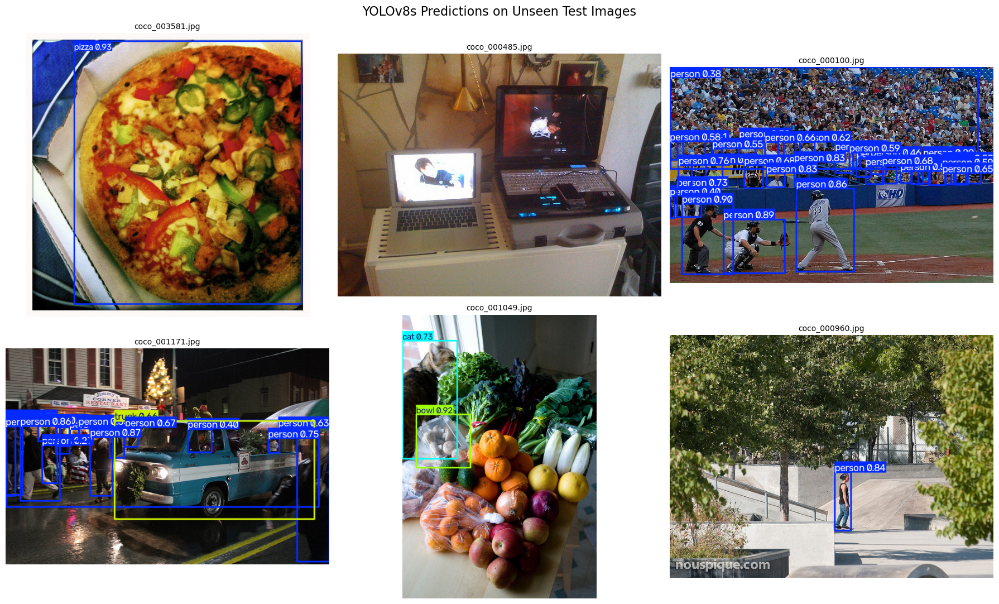

TEST PREDICTION VISUALIZATION COMPLETE
Images visualized : 6
Confidence        : 0.25
Saved to          : E:\SmartVision-AI\results\detection\yolov8s_final_test_predictions.png

✅ Prediction visualization saved


In [11]:
# ============================================================
# PHASE 3 - STEP 3.4
# VISUALIZE YOLOV8S TEST PREDICTIONS
# ============================================================

import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

TEST_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images\test"
)

# Collect test images
image_files = (
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.jpeg")) +
    list(TEST_IMAGES.glob("*.png"))
)

random.seed(42)
sample_images = random.sample(image_files, 6)

# Run predictions
prediction_results = final_yolo.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

# Display results
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, result, image_path in zip(
    axes,
    prediction_results,
    sample_images
):
    plotted = result.plot()

    # Ultralytics returns BGR
    plotted = plotted[:, :, ::-1]

    ax.imshow(plotted)
    ax.set_title(image_path.name, fontsize=10)
    ax.axis("off")

plt.suptitle(
    "YOLOv8s Predictions on Unseen Test Images",
    fontsize=16
)

plt.tight_layout()

OUTPUT_PLOT = Path(
    r"E:\SmartVision-AI\results\detection"
) / "yolov8s_final_test_predictions.png"

plt.savefig(
    OUTPUT_PLOT,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("TEST PREDICTION VISUALIZATION COMPLETE")
print("=" * 70)
print("Images visualized :", len(sample_images))
print("Confidence        : 0.25")
print("Saved to          :", OUTPUT_PLOT)

print("\n✅ Prediction visualization saved")

In [1]:
# ============================================================
# PHASE 3 - STEP 3.4
# RELOAD FINAL YOLOV8S AFTER CUDA OOM
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import torch

FINAL_YOLO_MODEL = Path(
    r"E:\SmartVision-AI\runs\detection\yolov8s_final\weights\best.pt"
)

TEST_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images\test"
)

final_yolo = YOLO(str(FINAL_YOLO_MODEL))

print("=" * 65)
print("FINAL YOLOV8S RELOADED")
print("=" * 65)
print("Checkpoint :", FINAL_YOLO_MODEL)
print("Classes    :", len(final_yolo.names))
print("CUDA       :", torch.cuda.is_available())
print("GPU        :", torch.cuda.get_device_name(0))

print("\n✅ Ready for memory-safe failure analysis")

FINAL YOLOV8S RELOADED
Checkpoint : E:\SmartVision-AI\runs\detection\yolov8s_final\weights\best.pt
Classes    : 25
CUDA       : True
GPU        : NVIDIA GeForce RTX 4050 Laptop GPU

✅ Ready for memory-safe failure analysis


In [2]:
# ============================================================
# PHASE 3 - STEP 3.4
# MEMORY-SAFE YOLOV8S FAILURE / DIFFICULT CASE ANALYSIS
# ============================================================

from pathlib import Path
import torch
import gc

TEST_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images\test"
)

image_files = sorted(
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.jpeg")) +
    list(TEST_IMAGES.glob("*.png"))
)

no_detection = []
low_confidence = []

print("=" * 70)
print("MEMORY-SAFE YOLOV8S FAILURE ANALYSIS")
print("=" * 70)
print("Test images :", len(image_files))
print("\nProcessing...")

for idx, image_path in enumerate(image_files, start=1):

    # Process ONE image only
    result = final_yolo.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    num_detections = len(result.boxes)

    if num_detections == 0:
        no_detection.append(image_path.name)

    else:
        max_conf = float(result.boxes.conf.max().cpu())

        if max_conf < 0.50:
            low_confidence.append(
                (image_path.name, max_conf, num_detections)
            )

    # Release result before next image
    del result

    if idx % 50 == 0:
        gc.collect()
        torch.cuda.empty_cache()
        print(f"Processed {idx}/{len(image_files)}")

gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("FAILURE / DIFFICULT CASE SUMMARY")
print("=" * 70)

print("Total test images          :", len(image_files))
print("No detections              :", len(no_detection))
print("Only low-confidence output :", len(low_confidence))

print("\nSample images with NO detections:")
for name in no_detection[:10]:
    print(" -", name)

print("\nSample low-confidence cases:")
for name, conf, count in low_confidence[:10]:
    print(
        f" - {name:<20} "
        f"max_conf={conf:.3f} | detections={count}"
    )

print("\n✅ Memory-safe difficult-case analysis complete")

MEMORY-SAFE YOLOV8S FAILURE ANALYSIS
Test images : 356

Processing...
Processed 50/356
Processed 100/356
Processed 150/356
Processed 200/356
Processed 250/356
Processed 300/356
Processed 350/356

FAILURE / DIFFICULT CASE SUMMARY
Total test images          : 356
No detections              : 24
Only low-confidence output : 27

Sample images with NO detections:
 - coco_000024.jpg
 - coco_000061.jpg
 - coco_000102.jpg
 - coco_000169.jpg
 - coco_000259.jpg
 - coco_000282.jpg
 - coco_000328.jpg
 - coco_000757.jpg
 - coco_000761.jpg
 - coco_000766.jpg

Sample low-confidence cases:
 - coco_000005.jpg      max_conf=0.381 | detections=1
 - coco_000018.jpg      max_conf=0.266 | detections=1
 - coco_000068.jpg      max_conf=0.448 | detections=2
 - coco_000157.jpg      max_conf=0.271 | detections=1
 - coco_000351.jpg      max_conf=0.317 | detections=1
 - coco_000357.jpg      max_conf=0.440 | detections=1
 - coco_000555.jpg      max_conf=0.359 | detections=2
 - coco_000632.jpg      max_conf=0.365 | 

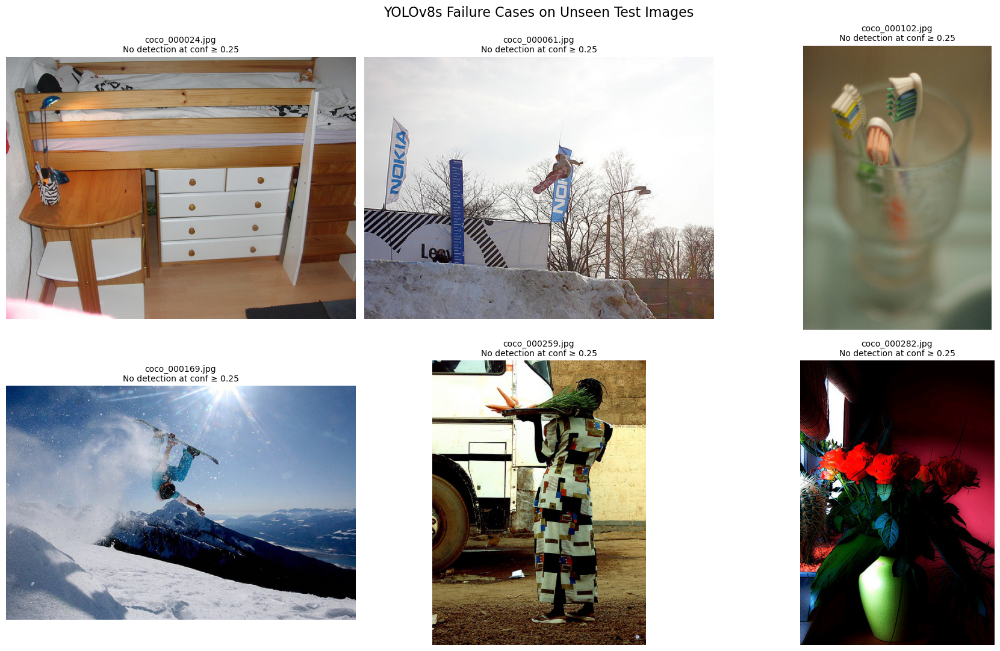

FAILURE-CASE VISUALIZATION COMPLETE
Failure images : 6
Saved to       : E:\SmartVision-AI\results\detection\yolov8s_final_failure_cases.png

✅ Failure-case visualization saved


In [3]:
# ============================================================
# PHASE 3 - STEP 3.4
# VISUALIZE YOLOV8S NO-DETECTION FAILURE CASES
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

TEST_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images\test"
)

# Take first 6 genuine no-detection cases
failure_samples = no_detection[:6]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, image_name in zip(axes, failure_samples):

    image_path = TEST_IMAGES / image_name
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{image_name}\nNo detection at conf ≥ 0.25",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "YOLOv8s Failure Cases on Unseen Test Images",
    fontsize=16
)

plt.tight_layout()

FAILURE_PLOT = Path(
    r"E:\SmartVision-AI\results\detection"
) / "yolov8s_final_failure_cases.png"

plt.savefig(
    FAILURE_PLOT,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("=" * 70)
print("FAILURE-CASE VISUALIZATION COMPLETE")
print("=" * 70)
print("Failure images :", len(failure_samples))
print("Saved to       :", FAILURE_PLOT)

print("\n✅ Failure-case visualization saved")

In [4]:
# ============================================================
# PHASE 3 - FINAL DETECTION SUMMARY
# ============================================================

import json
from pathlib import Path

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

phase3_summary = {
    "selected_model": "YOLOv8s",

    "checkpoint": (
        r"E:\SmartVision-AI\runs\detection"
        r"\yolov8s_final\weights\best.pt"
    ),

    "dataset": {
        "classes": 25,
        "test_images": 356,
        "test_instances": 1714
    },

    "test_metrics": {
        "precision": 0.5580,
        "recall": 0.4336,
        "map50": 0.4463,
        "map50_95": 0.3089,
        "inference_ms_per_image": 8.66
    },

    "failure_analysis": {
        "confidence_threshold": 0.25,
        "no_detection_images": 24,
        "low_confidence_images": 27,
        "observed_limitations": [
            "small or distant objects",
            "object occlusion",
            "unusual viewpoints and poses",
            "cluttered scenes",
            "blur or shallow depth of field",
            "difficult lighting and strong shadows"
        ]
    },

    "artifacts": {
        "metrics":
            "yolov8s_final_test_metrics.json",
        "prediction_visualization":
            "yolov8s_final_test_predictions.png",
        "failure_visualization":
            "yolov8s_final_failure_cases.png"
    },

    "target_note": (
        "The project specification listed mAP@0.50 > 85% "
        "as an expected target. The final measured test "
        "mAP@0.50 was 44.63%. The measured result is reported "
        "without alteration."
    )
}

SUMMARY_FILE = (
    RESULTS_DIR /
    "phase3_final_detection_summary.json"
)

with open(SUMMARY_FILE, "w") as f:
    json.dump(phase3_summary, f, indent=4)

print("=" * 70)
print("PHASE 3 FINAL SUMMARY SAVED")
print("=" * 70)

print("Selected model : YOLOv8s")
print("Precision      : 55.80%")
print("Recall         : 43.36%")
print("mAP@0.50       : 44.63%")
print("mAP@0.50:0.95  : 30.89%")
print("Inference      : 8.66 ms/image")
print("No detections  : 24 / 356")
print("Low confidence : 27 / 356")

print("\nSaved to:")
print(SUMMARY_FILE)

print("\n✅ Phase 3 detection results documented")

PHASE 3 FINAL SUMMARY SAVED
Selected model : YOLOv8s
Precision      : 55.80%
Recall         : 43.36%
mAP@0.50       : 44.63%
mAP@0.50:0.95  : 30.89%
Inference      : 8.66 ms/image
No detections  : 24 / 356
Low confidence : 27 / 356

Saved to:
E:\SmartVision-AI\results\detection\phase3_final_detection_summary.json

✅ Phase 3 detection results documented


In [5]:
# ============================================================
# PHASE 3.5 - DETECTION PERFORMANCE OPTIMIZATION
# STEP 1: ANALYZE TRAINING OBJECT DISTRIBUTION
# ============================================================

from pathlib import Path
from collections import Counter

TRAIN_LABELS = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels\train"
)

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse",
    "cow", "elephant", "bottle", "cup", "bowl",
    "pizza", "cake", "chair", "potted plant", "bed"
]

object_counts = Counter()
image_counts = Counter()

label_files = list(TRAIN_LABELS.glob("*.txt"))

for label_file in label_files:

    classes_in_image = set()

    with open(label_file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            object_counts[class_id] += 1
            classes_in_image.add(class_id)

    for class_id in classes_in_image:
        image_counts[class_id] += 1


print("=" * 76)
print("TRAINING DATA DISTRIBUTION")
print("=" * 76)

print(
    f"{'ID':<4}"
    f"{'Class':<18}"
    f"{'Images':>10}"
    f"{'Objects':>12}"
    f"{'Objects/Image':>16}"
)

print("-" * 76)

for class_id, class_name in enumerate(CLASS_NAMES):

    images = image_counts[class_id]
    objects = object_counts[class_id]

    ratio = objects / images if images else 0

    print(
        f"{class_id:<4}"
        f"{class_name:<18}"
        f"{images:>10}"
        f"{objects:>12}"
        f"{ratio:>16.2f}"
    )

print("-" * 76)

print("Training images :", len(label_files))
print("Training objects:", sum(object_counts.values()))

print("\nLeast represented classes by OBJECT COUNT:")

for class_id, count in sorted(
    object_counts.items(),
    key=lambda x: x[1]
)[:10]:

    print(
        f"{CLASS_NAMES[class_id]:<18} "
        f"{count:>5} objects | "
        f"{image_counts[class_id]:>4} images"
    )

print("\n✅ Training distribution analysis complete")

TRAINING DATA DISTRIBUTION
ID  Class                 Images     Objects   Objects/Image
----------------------------------------------------------------------------
0   person                   560        2628            4.69
1   bicycle                   79         189            2.39
2   car                      206         751            3.65
3   motorcycle                78         129            1.65
4   airplane                  70         133            1.90
5   bus                       76         116            1.53
6   train                     71          94            1.32
7   truck                    111         186            1.68
8   traffic light             76         230            3.03
9   stop sign                 70          75            1.07
10  bench                     92         164            1.78
11  bird                      71         259            3.65
12  cat                       72          82            1.14
13  dog                       71         1

In [6]:
# ============================================================
# PHASE 3.5 - STEP 2
# ANALYZE BOUNDING BOX SIZE DISTRIBUTION BY CLASS
# ============================================================

from pathlib import Path
from collections import defaultdict
import numpy as np

TRAIN_LABELS = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels\train"
)

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse",
    "cow", "elephant", "bottle", "cup", "bowl",
    "pizza", "cake", "chair", "potted plant", "bed"
]

box_areas = defaultdict(list)

for label_file in TRAIN_LABELS.glob("*.txt"):

    with open(label_file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            # YOLO normalized width and height
            width = float(parts[3])
            height = float(parts[4])

            area = width * height

            box_areas[class_id].append(area)


print("=" * 92)
print("BOUNDING BOX SIZE DISTRIBUTION")
print("=" * 92)

print(
    f"{'Class':<18}"
    f"{'Boxes':>8}"
    f"{'Mean Area %':>14}"
    f"{'Median %':>12}"
    f"{'<1%':>8}"
    f"{'<5%':>8}"
)

print("-" * 92)

for class_id, class_name in enumerate(CLASS_NAMES):

    areas = np.array(box_areas[class_id])

    mean_area = np.mean(areas) * 100
    median_area = np.median(areas) * 100

    tiny = np.sum(areas < 0.01)
    small = np.sum(areas < 0.05)

    print(
        f"{class_name:<18}"
        f"{len(areas):>8}"
        f"{mean_area:>14.2f}"
        f"{median_area:>12.2f}"
        f"{tiny:>8}"
        f"{small:>8}"
    )


# ------------------------------------------------------------
# Overall statistics
# ------------------------------------------------------------

all_areas = np.concatenate(
    [np.array(v) for v in box_areas.values()]
)

print("-" * 92)

print(f"Total boxes              : {len(all_areas)}")
print(f"Mean box area            : {np.mean(all_areas)*100:.2f}%")
print(f"Median box area          : {np.median(all_areas)*100:.2f}%")

print(
    f"Boxes occupying <1% image: "
    f"{np.sum(all_areas < 0.01)} "
    f"({np.mean(all_areas < 0.01)*100:.2f}%)"
)

print(
    f"Boxes occupying <5% image: "
    f"{np.sum(all_areas < 0.05)} "
    f"({np.mean(all_areas < 0.05)*100:.2f}%)"
)

print("\n✅ Bounding-box size analysis complete")

BOUNDING BOX SIZE DISTRIBUTION
Class                Boxes   Mean Area %    Median %     <1%     <5%
--------------------------------------------------------------------------------------------
person                2628          5.53        0.84    1392    2022
bicycle                189          4.62        1.17      89     151
car                    751          2.54        0.32     544     687
motorcycle             129         15.51        3.65      39      71
airplane               133         14.06        4.54      41      70
bus                    116         16.70        6.48      26      48
train                   94         26.02       21.56       7      22
truck                  186          5.64        1.14      88     146
traffic light          230          0.79        0.11     204     222
stop sign               75          8.83        3.24      28      46
bench                  164          7.10        1.12      77     123
bird                   259          4.25        

In [7]:
# ============================================================
# PHASE 3.5 - STEP 3
# ANALYZE OBJECT PIXEL SIZE AT YOLO TRAINING RESOLUTION
# ============================================================

from pathlib import Path
from collections import defaultdict
import numpy as np

TRAIN_LABELS = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels\train"
)

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse",
    "cow", "elephant", "bottle", "cup", "bowl",
    "pizza", "cake", "chair", "potted plant", "bed"
]

IMG_SIZE = 640

box_sizes = defaultdict(list)

for label_file in TRAIN_LABELS.glob("*.txt"):

    with open(label_file, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            w_norm = float(parts[3])
            h_norm = float(parts[4])

            w_px = w_norm * IMG_SIZE
            h_px = h_norm * IMG_SIZE

            box_sizes[class_id].append(
                (w_px, h_px)
            )


print("=" * 105)
print("OBJECT PIXEL SIZE AT 640x640")
print("=" * 105)

print(
    f"{'Class':<18}"
    f"{'Boxes':>7}"
    f"{'Med W':>10}"
    f"{'Med H':>10}"
    f"{'<16px':>10}"
    f"{'<32px':>10}"
    f"{'<64px':>10}"
)

print("-" * 105)

all_min_dimensions = []

for class_id, class_name in enumerate(CLASS_NAMES):

    sizes = np.array(box_sizes[class_id])

    widths = sizes[:, 0]
    heights = sizes[:, 1]

    # Smaller dimension of each box
    min_dims = np.minimum(widths, heights)

    all_min_dimensions.extend(min_dims)

    below_16 = np.sum(min_dims < 16)
    below_32 = np.sum(min_dims < 32)
    below_64 = np.sum(min_dims < 64)

    print(
        f"{class_name:<18}"
        f"{len(sizes):>7}"
        f"{np.median(widths):>10.1f}"
        f"{np.median(heights):>10.1f}"
        f"{below_16:>10}"
        f"{below_32:>10}"
        f"{below_64:>10}"
    )


all_min_dimensions = np.array(all_min_dimensions)

print("-" * 105)

print("Total objects :", len(all_min_dimensions))

print(
    f"Objects with minimum dimension <16 px : "
    f"{np.sum(all_min_dimensions < 16)} "
    f"({np.mean(all_min_dimensions < 16)*100:.2f}%)"
)

print(
    f"Objects with minimum dimension <32 px : "
    f"{np.sum(all_min_dimensions < 32)} "
    f"({np.mean(all_min_dimensions < 32)*100:.2f}%)"
)

print(
    f"Objects with minimum dimension <64 px : "
    f"{np.sum(all_min_dimensions < 64)} "
    f"({np.mean(all_min_dimensions < 64)*100:.2f}%)"
)

print("\nMedian minimum object dimension:",
      f"{np.median(all_min_dimensions):.1f}px")

print("\n✅ Pixel-size analysis complete")

OBJECT PIXEL SIZE AT 640x640
Class               Boxes     Med W     Med H     <16px     <32px     <64px
---------------------------------------------------------------------------------------------------------
person               2628      36.8      92.7       600      1202      1784
bicycle               189      56.0      83.9        18        70       108
car                   751      40.2      33.1       197       411       595
motorcycle            129      98.8     162.0         5        26        53
airplane              133     202.8     100.7        12        31        54
bus                   116     158.0     183.7         4        17        35
train                  94     360.1     248.4         1         6         9
truck                 186      68.0      67.4        17        53       106
traffic light         230      12.9      33.1       142       189       209
stop sign              75      82.5     120.7        12        19        31
bench                 164    

In [8]:
# ============================================================
# PHASE 3.5 - STEP 4
# CHECK YOLO LABEL CONSISTENCY / DUPLICATE BOXES
# ============================================================

from pathlib import Path
from collections import Counter

LABEL_ROOT = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels"
)

splits = ["train", "val", "test"]

print("=" * 78)
print("YOLO LABEL CONSISTENCY CHECK")
print("=" * 78)

total_files = 0
total_boxes = 0
duplicate_boxes = 0
invalid_class_ids = 0
invalid_coordinates = 0
empty_files = 0

for split in splits:

    split_dir = LABEL_ROOT / split
    files = list(split_dir.glob("*.txt"))

    split_boxes = 0
    split_duplicates = 0
    split_invalid = 0
    split_empty = 0

    for label_file in files:

        lines = [
            line.strip()
            for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            split_empty += 1
            continue

        # Exact duplicate annotation lines
        counts = Counter(lines)

        duplicates = sum(
            count - 1
            for count in counts.values()
            if count > 1
        )

        split_duplicates += duplicates

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                split_invalid += 1
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                split_invalid += 1
                continue

            if not 0 <= class_id < 25:
                invalid_class_ids += 1
                split_invalid += 1

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                invalid_coordinates += 1
                split_invalid += 1

            split_boxes += 1

    total_files += len(files)
    total_boxes += split_boxes
    duplicate_boxes += split_duplicates
    empty_files += split_empty

    print(
        f"{split.upper():<6} -> "
        f"Files: {len(files):>4} | "
        f"Boxes: {split_boxes:>5} | "
        f"Duplicates: {split_duplicates:>3} | "
        f"Invalid: {split_invalid:>3} | "
        f"Empty: {split_empty:>3}"
    )

print("-" * 78)

print("Total label files      :", total_files)
print("Total boxes            :", total_boxes)
print("Exact duplicate boxes  :", duplicate_boxes)
print("Invalid class IDs      :", invalid_class_ids)
print("Invalid coordinates    :", invalid_coordinates)
print("Empty label files      :", empty_files)

if (
    duplicate_boxes == 0
    and invalid_class_ids == 0
    and invalid_coordinates == 0
    and empty_files == 0
):
    print("\n✅ Existing YOLO label files are structurally clean")
else:
    print("\n⚠️ Annotation issues detected")

print("=" * 78)

YOLO LABEL CONSISTENCY CHECK
TRAIN  -> Files: 1108 | Boxes:  7418 | Duplicates:   0 | Invalid:   0 | Empty:   0
VAL    -> Files:  353 | Boxes:  1856 | Duplicates:   0 | Invalid:   0 | Empty:   0
TEST   -> Files:  356 | Boxes:  1714 | Duplicates:   0 | Invalid:   0 | Empty:   0
------------------------------------------------------------------------------
Total label files      : 1817
Total boxes            : 10988
Exact duplicate boxes  : 0
Invalid class IDs      : 0
Invalid coordinates    : 0
Empty label files      : 0

✅ Existing YOLO label files are structurally clean


In [9]:
# ============================================================
# PHASE 3.5 - STEP 5
# WEAK CLASS DIAGNOSIS
# ============================================================

# Final YOLOv8s TEST mAP@0.50 from Ultralytics evaluation
TEST_MAP50 = {
    "person": 0.632,
    "bicycle": 0.517,
    "car": 0.478,
    "motorcycle": 0.559,
    "airplane": 0.660,
    "bus": 0.567,
    "train": 0.430,
    "truck": 0.248,
    "traffic light": 0.329,
    "stop sign": 0.700,
    "bench": 0.156,
    "bird": 0.283,
    "cat": 0.636,
    "dog": 0.437,
    "horse": 0.405,
    "cow": 0.584,
    "elephant": 0.827,
    "bottle": 0.287,
    "cup": 0.280,
    "bowl": 0.332,
    "pizza": 0.727,
    "cake": 0.363,
    "chair": 0.129,
    "potted plant": 0.355,
    "bed": 0.237
}

print("=" * 105)
print("WEAK CLASS DIAGNOSIS")
print("=" * 105)

print(
    f"{'Class':<18}"
    f"{'Train Obj':>10}"
    f"{'Median Area %':>16}"
    f"{'Test mAP50':>14}"
    f"{'Status':>15}"
)

print("-" * 105)

rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    objects = object_counts[class_id]

    areas = np.array(box_areas[class_id])
    median_area = np.median(areas) * 100

    map50 = TEST_MAP50[class_name]

    if map50 < 0.30:
        status = "VERY WEAK"
    elif map50 < 0.50:
        status = "WEAK"
    elif map50 < 0.70:
        status = "MODERATE"
    else:
        status = "STRONG"

    rows.append(
        (
            class_name,
            objects,
            median_area,
            map50,
            status
        )
    )


# Sort weakest mAP first
rows.sort(key=lambda x: x[3])

for class_name, objects, median_area, map50, status in rows:

    print(
        f"{class_name:<18}"
        f"{objects:>10}"
        f"{median_area:>16.2f}"
        f"{map50*100:>13.1f}%"
        f"{status:>15}"
    )

print("-" * 105)

very_weak = [x[0] for x in rows if x[3] < 0.30]
weak = [x[0] for x in rows if 0.30 <= x[3] < 0.50]

print("\nVERY WEAK (<30% mAP50):")
print(very_weak)

print("\nWEAK (30-50% mAP50):")
print(weak)

print("\nNumber below 50% mAP50:",
      len(very_weak) + len(weak),
      "/ 25")

print("\n✅ Weak-class diagnosis complete")

WEAK CLASS DIAGNOSIS
Class              Train Obj   Median Area %    Test mAP50         Status
---------------------------------------------------------------------------------------------------------
chair                    428            1.62         12.9%      VERY WEAK
bench                    164            1.12         15.6%      VERY WEAK
bed                       75           43.57         23.7%      VERY WEAK
truck                    186            1.14         24.8%      VERY WEAK
cup                      252            0.56         28.0%      VERY WEAK
bird                     259            0.38         28.3%      VERY WEAK
bottle                   288            0.33         28.7%      VERY WEAK
traffic light            230            0.11         32.9%           WEAK
bowl                     183            0.90         33.2%           WEAK
potted plant             133            1.48         35.5%           WEAK
cake                     189            1.44         36.3% 

In [10]:
# ============================================================
# PHASE 3.5 - STEP 6
# CLASS IMAGE COVERAGE ACROSS TRAIN / VAL / TEST
# ============================================================

from pathlib import Path
from collections import defaultdict

LABEL_ROOT = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\labels"
)

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse",
    "cow", "elephant", "bottle", "cup", "bowl",
    "pizza", "cake", "chair", "potted plant", "bed"
]

splits = ["train", "val", "test"]

coverage = {
    split: defaultdict(int)
    for split in splits
}

for split in splits:

    label_dir = LABEL_ROOT / split

    for label_file in label_dir.glob("*.txt"):

        classes_present = set()

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                classes_present.add(class_id)

        for class_id in classes_present:
            coverage[split][class_id] += 1


print("=" * 78)
print("CLASS IMAGE COVERAGE")
print("=" * 78)

print(
    f"{'Class':<18}"
    f"{'Train':>10}"
    f"{'Val':>10}"
    f"{'Test':>10}"
    f"{'Total':>10}"
)

print("-" * 78)

for class_id, class_name in enumerate(CLASS_NAMES):

    train_count = coverage["train"][class_id]
    val_count = coverage["val"][class_id]
    test_count = coverage["test"][class_id]

    total = train_count + val_count + test_count

    print(
        f"{class_name:<18}"
        f"{train_count:>10}"
        f"{val_count:>10}"
        f"{test_count:>10}"
        f"{total:>10}"
    )

print("-" * 78)

print("\nClasses with fewer than 100 total source images:")

for class_id, class_name in enumerate(CLASS_NAMES):

    total = (
        coverage["train"][class_id]
        + coverage["val"][class_id]
        + coverage["test"][class_id]
    )

    if total < 100:
        print(f"{class_name:<18} {total}")

print("\n✅ Class image coverage analysis complete")

CLASS IMAGE COVERAGE
Class                  Train       Val      Test     Total
------------------------------------------------------------------------------
person                   560       162       175       897
bicycle                   79        17        15       111
car                      206        49        51       306
motorcycle                78        16        16       110
airplane                  70        15        15       100
bus                       76        15        15       106
train                     71        15        18       104
truck                    111        23        23       157
traffic light             76        16        15       107
stop sign                 70        15        15       100
bench                     92        19        21       132
bird                      71        15        16       102
cat                       72        15        15       102
dog                       71        17        15       103
horse          

In [11]:
# ============================================================
# PHASE 3.5 - STEP 7A
# OPTIMIZED DETECTION DATASET - SETUP
# ============================================================

from pathlib import Path
import json

# ------------------------------------------------------------
# New dataset location
# ------------------------------------------------------------

OPT_BASE = Path(
    r"E:\SmartVision-AI\data\optimized_detection"
)

# Keep original final_dataset completely untouched
ORIGINAL_DATASET = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection"
)

# ------------------------------------------------------------
# 25 selected COCO classes
# Original COCO category IDs
# ------------------------------------------------------------

SELECTED_CLASSES = {
    "person": 0,
    "bicycle": 1,
    "car": 2,
    "motorcycle": 3,
    "airplane": 4,
    "bus": 5,
    "train": 6,
    "truck": 7,
    "traffic light": 9,
    "stop sign": 11,
    "bench": 13,
    "bird": 14,
    "cat": 15,
    "dog": 16,
    "horse": 17,
    "cow": 19,
    "elephant": 20,
    "bottle": 39,
    "cup": 41,
    "bowl": 45,
    "pizza": 53,
    "cake": 55,
    "chair": 56,
    "potted plant": 58,
    "bed": 59
}

# ------------------------------------------------------------
# Contiguous YOLO class IDs 0-24
# ------------------------------------------------------------

CLASS_NAMES = list(SELECTED_CLASSES.keys())

COCO_TO_YOLO = {
    coco_id: yolo_id
    for yolo_id, coco_id
    in enumerate(SELECTED_CLASSES.values())
}

# ------------------------------------------------------------
# Create folder structure
# ------------------------------------------------------------

for split in ["train", "val", "test"]:

    (OPT_BASE / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (OPT_BASE / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# Save class configuration
# ------------------------------------------------------------

config = {
    "num_classes": len(CLASS_NAMES),
    "class_names": CLASS_NAMES,
    "selected_coco_ids": SELECTED_CLASSES,
    "coco_to_yolo": COCO_TO_YOLO,
    "purpose": "Phase 3.5 optimized YOLO detection dataset"
}

config_path = OPT_BASE / "optimization_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 72)
print("OPTIMIZED DETECTION DATASET SETUP")
print("=" * 72)

print("Original dataset:")
print(ORIGINAL_DATASET)

print("\nOptimized dataset:")
print(OPT_BASE)

print("\nNumber of classes:", len(CLASS_NAMES))

print("\nYOLO class mapping:")

for yolo_id, name in enumerate(CLASS_NAMES):
    print(
        f"{yolo_id:>2} -> "
        f"{name:<15} "
        f"(COCO ID {SELECTED_CLASSES[name]})"
    )

print("\nFolder structure created successfully.")
print("Original final_dataset has NOT been modified.")

print("\nConfig saved:")
print(config_path)

print("\n✅ STEP 7A COMPLETE")

OPTIMIZED DETECTION DATASET SETUP
Original dataset:
E:\SmartVision-AI\data\final_dataset\detection

Optimized dataset:
E:\SmartVision-AI\data\optimized_detection

Number of classes: 25

YOLO class mapping:
 0 -> person          (COCO ID 0)
 1 -> bicycle         (COCO ID 1)
 2 -> car             (COCO ID 2)
 3 -> motorcycle      (COCO ID 3)
 4 -> airplane        (COCO ID 4)
 5 -> bus             (COCO ID 5)
 6 -> train           (COCO ID 6)
 7 -> truck           (COCO ID 7)
 8 -> traffic light   (COCO ID 9)
 9 -> stop sign       (COCO ID 11)
10 -> bench           (COCO ID 13)
11 -> bird            (COCO ID 14)
12 -> cat             (COCO ID 15)
13 -> dog             (COCO ID 16)
14 -> horse           (COCO ID 17)
15 -> cow             (COCO ID 19)
16 -> elephant        (COCO ID 20)
17 -> bottle          (COCO ID 39)
18 -> cup             (COCO ID 41)
19 -> bowl            (COCO ID 45)
20 -> pizza           (COCO ID 53)
21 -> cake            (COCO ID 55)
22 -> chair           (COCO ID 56

In [12]:
# ============================================================
# PHASE 3.5 - STEP 7B
# DEFINE OPTIMIZED DATA COLLECTION TARGETS
# ============================================================

# ------------------------------------------------------------
# Performance groups from our YOLOv8s test evaluation
# ------------------------------------------------------------

VERY_WEAK = [
    "chair",
    "bench",
    "bed",
    "truck",
    "cup",
    "bird",
    "bottle"
]

WEAK = [
    "traffic light",
    "bowl",
    "potted plant",
    "cake",
    "horse",
    "train",
    "dog",
    "car"
]

MODERATE = [
    "bicycle",
    "motorcycle",
    "bus",
    "cow",
    "person",
    "cat",
    "airplane"
]

STRONG = [
    "stop sign",
    "pizza",
    "elephant"
]

# ------------------------------------------------------------
# Desired number of source images containing each class
# ------------------------------------------------------------

TARGET_IMAGES = {}

for name in VERY_WEAK:
    TARGET_IMAGES[name] = 400

for name in WEAK:
    TARGET_IMAGES[name] = 350

for name in MODERATE:
    TARGET_IMAGES[name] = 250

for name in STRONG:
    TARGET_IMAGES[name] = 200


# ------------------------------------------------------------
# Additional priority for extremely small-object classes
# ------------------------------------------------------------

SMALL_OBJECT_PRIORITY = [
    "traffic light",
    "bottle",
    "cup",
    "car",
    "bird"
]


# ------------------------------------------------------------
# Display strategy
# ------------------------------------------------------------

print("=" * 78)
print("OPTIMIZED DATA COLLECTION STRATEGY")
print("=" * 78)

print(
    f"{'Class':<18}"
    f"{'Group':<15}"
    f"{'Target Images':>15}"
    f"{'Small Obj':>15}"
)

print("-" * 78)

for name in CLASS_NAMES:

    if name in VERY_WEAK:
        group = "VERY WEAK"

    elif name in WEAK:
        group = "WEAK"

    elif name in MODERATE:
        group = "MODERATE"

    else:
        group = "STRONG"

    small_priority = (
        "YES"
        if name in SMALL_OBJECT_PRIORITY
        else "NO"
    )

    print(
        f"{name:<18}"
        f"{group:<15}"
        f"{TARGET_IMAGES[name]:>15}"
        f"{small_priority:>15}"
    )


print("-" * 78)

print(
    "Total class-image target:",
    sum(TARGET_IMAGES.values())
)

print("\nImportant:")
print("• These are class-image targets, NOT necessarily unique-image count.")
print("• One COCO image may satisfy multiple classes.")
print("• We will keep every selected-class annotation present in an accepted image.")
print("• Original final_dataset remains untouched.")

print("\n✅ STEP 7B COMPLETE")

OPTIMIZED DATA COLLECTION STRATEGY
Class             Group            Target Images      Small Obj
------------------------------------------------------------------------------
person            MODERATE                   250             NO
bicycle           MODERATE                   250             NO
car               WEAK                       350            YES
motorcycle        MODERATE                   250             NO
airplane          MODERATE                   250             NO
bus               MODERATE                   250             NO
train             WEAK                       350             NO
truck             VERY WEAK                  400             NO
traffic light     WEAK                       350            YES
stop sign         STRONG                     200             NO
bench             VERY WEAK                  400             NO
bird              VERY WEAK                  400            YES
cat               MODERATE                   250      

In [13]:
# ============================================================
# PHASE 3.5 - STEP 7C-1
# OPEN FRESH COCO STREAM + VERIFY SAMPLE FORMAT
# ============================================================

from datasets import load_dataset

print("Opening COCO streaming dataset...")

coco_stream = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

print("✅ COCO stream opened")

# ------------------------------------------------------------
# Inspect one sample
# ------------------------------------------------------------

sample = next(iter(coco_stream))

print("\n" + "=" * 72)
print("SAMPLE STRUCTURE")
print("=" * 72)

print("Top-level keys:")
print(sample.keys())

print("\nImage:")
print(type(sample["image"]))
print("Size:", sample["image"].size)

print("\nObjects keys:")
print(sample["objects"].keys())

print("\nNumber of objects:")
print(len(sample["objects"]["bbox"]))

print("\nFirst few category IDs:")
print(sample["objects"]["category"][:10])

print("\nFirst few bounding boxes:")
print(sample["objects"]["bbox"][:5])

# ------------------------------------------------------------
# Verify bbox interpretation
# Expected from our corrected COCO pipeline:
# [x1, y1, x2, y2]
# ------------------------------------------------------------

if len(sample["objects"]["bbox"]) > 0:

    bbox = sample["objects"]["bbox"][0]

    x1, y1, x2, y2 = bbox

    print("\nFirst bbox interpreted as XYXY:")
    print("x1 =", x1)
    print("y1 =", y1)
    print("x2 =", x2)
    print("y2 =", y2)

    print("\nCalculated size:")
    print("width  =", x2 - x1)
    print("height =", y2 - y1)

    if x2 > x1 and y2 > y1:
        print("\n✅ BBOX is valid under XYXY interpretation")
    else:
        print("\n⚠️ BBOX interpretation needs investigation")

print("\n" + "=" * 72)
print("STEP 7C-1 COMPLETE")
print("=" * 72)

Opening COCO streaming dataset...


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

✅ COCO stream opened

SAMPLE STRUCTURE
Top-level keys:
dict_keys(['image_id', 'image', 'width', 'height', 'objects'])

Image:
<class 'PIL.JpegImagePlugin.JpegImageFile'>
Size: (640, 480)

Objects keys:
dict_keys(['bbox_id', 'category', 'bbox', 'area'])

Number of objects:
8

First few category IDs:
[45, 45, 50, 45, 49, 49, 49, 49]

First few bounding boxes:
[[1.08, 187.69, 612.6700000000001, 473.53], [311.73, 4.31, 631.01, 232.99], [249.6, 229.27, 565.84, 474.35], [0.0, 13.51, 434.48, 388.63], [376.2, 40.36, 451.75, 86.89]]

First bbox interpreted as XYXY:
x1 = 1.08
y1 = 187.69
x2 = 612.6700000000001
y2 = 473.53

Calculated size:
width  = 611.59
height = 285.84

✅ BBOX is valid under XYXY interpretation

STEP 7C-1 COMPLETE


In [14]:
# ============================================================
# PHASE 3.5 - STEP 7C-2
# SELECT OPTIMIZED COCO CANDIDATES IN MEMORY
# ============================================================

from datasets import load_dataset
from collections import defaultdict
import time

# Fresh stream
stream = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

# COCO category ID -> class name
COCO_ID_TO_NAME = {
    coco_id: name
    for name, coco_id in SELECTED_CLASSES.items()
}

# Selected image IDs for each target class
selected_by_class = defaultdict(set)

# All unique accepted image IDs
accepted_image_ids = set()

start_time = time.time()
scanned = 0

print("=" * 80)
print("SCANNING COCO FOR OPTIMIZED TRAINING CANDIDATES")
print("=" * 80)

for sample in stream:

    scanned += 1

    image_id = int(sample["image_id"])

    # Classes from our selected 25 that occur in this image
    present_classes = set()

    for category_id in sample["objects"]["category"]:

        if category_id in COCO_ID_TO_NAME:
            present_classes.add(
                COCO_ID_TO_NAME[category_id]
            )

    if not present_classes:
        continue

    # Does this image help at least one class
    # that has not yet reached its target?
    useful_classes = [
        name
        for name in present_classes
        if len(selected_by_class[name]) < TARGET_IMAGES[name]
    ]

    if not useful_classes:
        continue

    # Accept image once
    accepted_image_ids.add(image_id)

    # Important:
    # Credit the image to EVERY selected class present in it
    # that still needs examples.
    for name in useful_classes:

        selected_by_class[name].add(image_id)

    # Progress
    if scanned % 2000 == 0:

        remaining = sum(
            max(
                0,
                TARGET_IMAGES[name]
                - len(selected_by_class[name])
            )
            for name in CLASS_NAMES
        )

        print(
            f"Scanned: {scanned:>6} | "
            f"Unique accepted: {len(accepted_image_ids):>5} | "
            f"Remaining class-image targets: {remaining}"
        )

    # Stop once every class reaches target
    if all(
        len(selected_by_class[name]) >= TARGET_IMAGES[name]
        for name in CLASS_NAMES
    ):
        break


elapsed = time.time() - start_time

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CANDIDATE SELECTION RESULTS")
print("=" * 80)

print(
    f"{'Class':<18}"
    f"{'Target':>10}"
    f"{'Selected':>12}"
    f"{'Status':>12}"
)

print("-" * 80)

all_reached = True

for name in CLASS_NAMES:

    target = TARGET_IMAGES[name]
    selected = len(selected_by_class[name])

    status = (
        "OK"
        if selected >= target
        else "SHORT"
    )

    if status == "SHORT":
        all_reached = False

    print(
        f"{name:<18}"
        f"{target:>10}"
        f"{selected:>12}"
        f"{status:>12}"
    )

print("-" * 80)

print("Images scanned       :", scanned)
print("Unique accepted IDs  :", len(accepted_image_ids))
print("Elapsed time         :", f"{elapsed/60:.2f} minutes")

if all_reached:
    print("\n✅ ALL 25 COLLECTION TARGETS REACHED")
else:
    print("\n⚠️ Some classes did not reach their targets")

print("\nNo images have been written to disk yet.")
print("Original final_dataset remains untouched.")

print("\n✅ STEP 7C-2 COMPLETE")

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

SCANNING COCO FOR OPTIMIZED TRAINING CANDIDATES
Scanned:   2000 | Unique accepted:  1311 | Remaining class-image targets: 5713

CANDIDATE SELECTION RESULTS
Class                 Target    Selected      Status
--------------------------------------------------------------------------------
person                   250         250          OK
bicycle                  250         250          OK
car                      350         350          OK
motorcycle               250         250          OK
airplane                 250         250          OK
bus                      250         250          OK
train                    350         350          OK
truck                    400         400          OK
traffic light            350         350          OK
stop sign                200         200          OK
bench                    400         400          OK
bird                     400         400          OK
cat                      250         250          OK
dog                  

In [15]:
# ============================================================
# PHASE 3.5 - STEP 7C-3
# CHECK OPTIMIZED CANDIDATES AGAINST ORIGINAL VAL / TEST
# ============================================================

from pathlib import Path
import re

ORIGINAL_IMAGES = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection\images"
)

# ------------------------------------------------------------
# Extract numeric COCO image ID from filename
#
# Handles names such as:
# 000000123456.jpg
# coco_123456.jpg
# image_123456.jpg
# ------------------------------------------------------------

def extract_image_id(path):

    numbers = re.findall(r"\d+", path.stem)

    if not numbers:
        return None

    # Use last numeric component
    return int(numbers[-1])


original_ids = {}

for split in ["train", "val", "test"]:

    ids = set()

    for path in (ORIGINAL_IMAGES / split).glob("*"):

        image_id = extract_image_id(path)

        if image_id is not None:
            ids.add(image_id)

    original_ids[split] = ids


# ------------------------------------------------------------
# Check overlap
# ------------------------------------------------------------

candidate_ids = set(accepted_image_ids)

train_overlap = candidate_ids & original_ids["train"]
val_overlap = candidate_ids & original_ids["val"]
test_overlap = candidate_ids & original_ids["test"]

protected_eval_ids = (
    original_ids["val"] |
    original_ids["test"]
)

safe_candidate_ids = (
    candidate_ids - protected_eval_ids
)


print("=" * 78)
print("OPTIMIZED CANDIDATE LEAKAGE CHECK")
print("=" * 78)

print("Original train IDs :", len(original_ids["train"]))
print("Original val IDs   :", len(original_ids["val"]))
print("Original test IDs  :", len(original_ids["test"]))

print("\nOptimized candidate IDs :", len(candidate_ids))

print("\nOverlap with original train :", len(train_overlap))
print("Overlap with original val   :", len(val_overlap))
print("Overlap with original test  :", len(test_overlap))

print("\nProtected val+test IDs :", len(protected_eval_ids))

print(
    "Safe optimized candidates after excluding val/test:",
    len(safe_candidate_ids)
)

removed = len(candidate_ids) - len(safe_candidate_ids)

print("\nCandidates removed for leakage protection:", removed)

# ------------------------------------------------------------
# Sanity assertions
# ------------------------------------------------------------

assert len(safe_candidate_ids & original_ids["val"]) == 0
assert len(safe_candidate_ids & original_ids["test"]) == 0

print("\n✅ ZERO VAL OVERLAP AFTER FILTERING")
print("✅ ZERO TEST OVERLAP AFTER FILTERING")

print("\nNo files modified.")
print("No images written yet.")

print("\n✅ STEP 7C-3 COMPLETE")

OPTIMIZED CANDIDATE LEAKAGE CHECK
Original train IDs : 1108
Original val IDs   : 353
Original test IDs  : 356

Optimized candidate IDs : 5652

Overlap with original train : 166
Overlap with original val   : 49
Overlap with original test  : 48

Protected val+test IDs : 709
Safe optimized candidates after excluding val/test: 5555

Candidates removed for leakage protection: 97

✅ ZERO VAL OVERLAP AFTER FILTERING
✅ ZERO TEST OVERLAP AFTER FILTERING

No files modified.
No images written yet.

✅ STEP 7C-3 COMPLETE


In [16]:
# ============================================================
# PHASE 3.5 - STEP 7C-4
# VERIFY CLASS TARGETS AFTER VAL / TEST LEAKAGE FILTERING
# ============================================================

from collections import defaultdict

# ------------------------------------------------------------
# Recalculate selected image counts using only SAFE candidates
# ------------------------------------------------------------

safe_selected_by_class = defaultdict(set)

for class_name in CLASS_NAMES:

    original_selected_ids = selected_by_class[class_name]

    safe_ids = (
        original_selected_ids
        & safe_candidate_ids
    )

    safe_selected_by_class[class_name] = safe_ids


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 86)
print("CLASS TARGETS AFTER LEAKAGE FILTERING")
print("=" * 86)

print(
    f"{'Class':<18}"
    f"{'Target':>10}"
    f"{'Before':>10}"
    f"{'After':>10}"
    f"{'Lost':>10}"
    f"{'Status':>12}"
)

print("-" * 86)

classes_below_target = []

for name in CLASS_NAMES:

    target = TARGET_IMAGES[name]

    before = len(selected_by_class[name])
    after = len(safe_selected_by_class[name])

    lost = before - after

    status = (
        "OK"
        if after >= target
        else "SHORT"
    )

    if after < target:
        classes_below_target.append(
            (name, target - after)
        )

    print(
        f"{name:<18}"
        f"{target:>10}"
        f"{before:>10}"
        f"{after:>10}"
        f"{lost:>10}"
        f"{status:>12}"
    )


print("-" * 86)

print(
    "Safe unique candidate images:",
    len(safe_candidate_ids)
)

if classes_below_target:

    print("\nClasses now below target:")

    for name, shortage in classes_below_target:
        print(
            f"{name:<18} needs "
            f"{shortage} additional images"
        )

    print(
        "\n⚠️ We need a small continuation scan "
        "before writing the dataset."
    )

else:

    print(
        "\n✅ ALL CLASS TARGETS STILL SATISFIED"
    )

print("\nNo files modified.")
print("No images written.")

print("\n✅ STEP 7C-4 COMPLETE")

CLASS TARGETS AFTER LEAKAGE FILTERING
Class                 Target    Before     After      Lost      Status
--------------------------------------------------------------------------------------
person                   250       250       202        48       SHORT
bicycle                  250       250       247         3       SHORT
car                      350       350       339        11       SHORT
motorcycle               250       250       244         6       SHORT
airplane                 250       250       243         7       SHORT
bus                      250       250       244         6       SHORT
train                    350       350       344         6       SHORT
truck                    400       400       395         5       SHORT
traffic light            350       350       345         5       SHORT
stop sign                200       200       199         1       SHORT
bench                    400       400       396         4       SHORT
bird                   

In [17]:
# ============================================================
# PHASE 3.5 - STEP 7C-5
# CONTINUE COCO SCAN AND FILL LEAKAGE-CREATED SHORTAGES
# ============================================================

from datasets import load_dataset
import time

# ------------------------------------------------------------
# Start from the leakage-safe selections
# ------------------------------------------------------------

final_selected_by_class = {
    name: set(safe_selected_by_class[name])
    for name in CLASS_NAMES
}

final_candidate_ids = set(safe_candidate_ids)

# IDs that must NEVER enter optimized training
protected_ids = set(original_ids["val"]) | set(original_ids["test"])

# ------------------------------------------------------------
# Fresh COCO stream
# ------------------------------------------------------------

stream = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

start_time = time.time()
scanned = 0
new_images_added = 0

print("=" * 82)
print("FILLING CLASS SHORTAGES")
print("=" * 82)

for sample in stream:

    scanned += 1

    image_id = int(sample["image_id"])

    # --------------------------------------------------------
    # Never use protected validation/test images
    # --------------------------------------------------------

    if image_id in protected_ids:
        continue

    # Already selected
    if image_id in final_candidate_ids:
        continue

    # --------------------------------------------------------
    # Find selected classes present in this image
    # --------------------------------------------------------

    present_classes = set()

    for category_id in sample["objects"]["category"]:

        if category_id in COCO_ID_TO_NAME:
            present_classes.add(
                COCO_ID_TO_NAME[category_id]
            )

    if not present_classes:
        continue

    # --------------------------------------------------------
    # Which classes still need images?
    # --------------------------------------------------------

    useful_classes = [
        name
        for name in present_classes
        if len(final_selected_by_class[name]) < TARGET_IMAGES[name]
    ]

    if not useful_classes:
        continue

    # --------------------------------------------------------
    # Accept this new image
    # --------------------------------------------------------

    final_candidate_ids.add(image_id)
    new_images_added += 1

    # Credit it only to classes that still need examples
    for name in useful_classes:
        final_selected_by_class[name].add(image_id)

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if scanned % 2000 == 0:

        remaining = sum(
            max(
                0,
                TARGET_IMAGES[name]
                - len(final_selected_by_class[name])
            )
            for name in CLASS_NAMES
        )

        print(
            f"Scanned: {scanned:>6} | "
            f"New images: {new_images_added:>4} | "
            f"Remaining targets: {remaining}"
        )

    # --------------------------------------------------------
    # Stop when all targets are restored
    # --------------------------------------------------------

    if all(
        len(final_selected_by_class[name]) >= TARGET_IMAGES[name]
        for name in CLASS_NAMES
    ):
        break


elapsed = time.time() - start_time

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\n" + "=" * 82)
print("FINAL LEAKAGE-SAFE COLLECTION")
print("=" * 82)

print(
    f"{'Class':<18}"
    f"{'Target':>10}"
    f"{'Final':>10}"
    f"{'Status':>12}"
)

print("-" * 82)

all_reached = True

for name in CLASS_NAMES:

    target = TARGET_IMAGES[name]
    count = len(final_selected_by_class[name])

    status = "OK" if count >= target else "SHORT"

    if count < target:
        all_reached = False

    print(
        f"{name:<18}"
        f"{target:>10}"
        f"{count:>10}"
        f"{status:>12}"
    )

print("-" * 82)

print("New replacement images added :", new_images_added)
print("Final unique candidate IDs   :", len(final_candidate_ids))
print("Images scanned               :", scanned)
print("Elapsed time                 :", f"{elapsed/60:.2f} minutes")

# ------------------------------------------------------------
# Leakage assertions
# ------------------------------------------------------------

assert len(final_candidate_ids & original_ids["val"]) == 0
assert len(final_candidate_ids & original_ids["test"]) == 0

print("\n✅ ZERO overlap with original validation")
print("✅ ZERO overlap with original test")

if all_reached:
    print("✅ ALL 25 COLLECTION TARGETS RESTORED")
else:
    print("⚠️ Some targets still need additional images")

print("\nNo image files have been written yet.")
print("Original final_dataset remains untouched.")

print("\n✅ STEP 7C-5 COMPLETE")

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

FILLING CLASS SHORTAGES

FINAL LEAKAGE-SAFE COLLECTION
Class                 Target     Final      Status
----------------------------------------------------------------------------------
person                   250       250          OK
bicycle                  250       250          OK
car                      350       350          OK
motorcycle               250       250          OK
airplane                 250       250          OK
bus                      250       250          OK
train                    350       350          OK
truck                    400       400          OK
traffic light            350       350          OK
stop sign                200       200          OK
bench                    400       400          OK
bird                     400       400          OK
cat                      250       250          OK
dog                      350       350          OK
horse                    350       350          OK
cow                      250       250        

In [18]:
# ============================================================
# PHASE 3.5 - STEP 7D
# WRITE OPTIMIZED TRAINING IMAGES + COMPLETE YOLO LABELS
# ============================================================

from datasets import load_dataset
from pathlib import Path
import time
import json

OPT_IMAGES = OPT_BASE / "images" / "train"
OPT_LABELS = OPT_BASE / "labels" / "train"

OPT_IMAGES.mkdir(parents=True, exist_ok=True)
OPT_LABELS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

assert len(final_candidate_ids & original_ids["val"]) == 0
assert len(final_candidate_ids & original_ids["test"]) == 0

print("=" * 82)
print("WRITING OPTIMIZED TRAINING DATASET")
print("=" * 82)

print("Images to save :", len(final_candidate_ids))
print("Image folder   :", OPT_IMAGES)
print("Label folder   :", OPT_LABELS)

# ------------------------------------------------------------
# Fresh COCO stream
# ------------------------------------------------------------

stream = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

saved_images = 0
saved_boxes = 0
scanned = 0
skipped_invalid_boxes = 0

saved_ids = set()

start_time = time.time()

# ------------------------------------------------------------
# Stream and save only selected IDs
# ------------------------------------------------------------

for sample in stream:

    scanned += 1

    image_id = int(sample["image_id"])

    if image_id not in final_candidate_ids:
        continue

    # Avoid accidental duplicate writing
    if image_id in saved_ids:
        continue

    image = sample["image"].convert("RGB")

    W, H = image.size

    yolo_lines = []

    # --------------------------------------------------------
    # Keep EVERY annotation belonging to our selected 25
    # --------------------------------------------------------

    categories = sample["objects"]["category"]
    bboxes = sample["objects"]["bbox"]

    for category_id, bbox in zip(categories, bboxes):

        if category_id not in COCO_TO_YOLO:
            continue

        yolo_id = COCO_TO_YOLO[category_id]

        # HF COCO bbox = XYXY
        x1, y1, x2, y2 = map(float, bbox)

        # Clip to image boundaries
        x1 = max(0.0, min(x1, W))
        y1 = max(0.0, min(y1, H))
        x2 = max(0.0, min(x2, W))
        y2 = max(0.0, min(y2, H))

        box_w = x2 - x1
        box_h = y2 - y1

        if box_w <= 0 or box_h <= 0:
            skipped_invalid_boxes += 1
            continue

        # YOLO normalized XYWH
        xc = ((x1 + x2) / 2.0) / W
        yc = ((y1 + y2) / 2.0) / H

        wn = box_w / W
        hn = box_h / H

        # Final safety
        if not (
            0 <= xc <= 1 and
            0 <= yc <= 1 and
            0 < wn <= 1 and
            0 < hn <= 1
        ):
            skipped_invalid_boxes += 1
            continue

        yolo_lines.append(
            f"{yolo_id} "
            f"{xc:.6f} "
            f"{yc:.6f} "
            f"{wn:.6f} "
            f"{hn:.6f}"
        )

    # Every selected candidate should contain >=1 target object
    if not yolo_lines:
        continue

    # --------------------------------------------------------
    # Save using COCO image ID as filename
    # --------------------------------------------------------

    stem = f"{image_id:012d}"

    image_path = OPT_IMAGES / f"{stem}.jpg"
    label_path = OPT_LABELS / f"{stem}.txt"

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    label_path.write_text(
        "\n".join(yolo_lines),
        encoding="utf-8"
    )

    saved_ids.add(image_id)

    saved_images += 1
    saved_boxes += len(yolo_lines)

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if saved_images % 500 == 0:

        elapsed = time.time() - start_time

        print(
            f"Saved {saved_images:>5}/{len(final_candidate_ids)} "
            f"| Boxes: {saved_boxes:>6} "
            f"| Scanned: {scanned:>6} "
            f"| Time: {elapsed/60:.1f} min"
        )

    if saved_images == len(final_candidate_ids):
        break


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

elapsed = time.time() - start_time

missing_ids = final_candidate_ids - saved_ids

print("\n" + "=" * 82)
print("OPTIMIZED TRAINING DATASET WRITE SUMMARY")
print("=" * 82)

print("Expected images       :", len(final_candidate_ids))
print("Saved images          :", saved_images)
print("Saved label files     :", len(list(OPT_LABELS.glob('*.txt'))))
print("Total selected boxes  :", saved_boxes)
print("Invalid boxes skipped :", skipped_invalid_boxes)
print("Missing image IDs     :", len(missing_ids))
print("COCO samples scanned  :", scanned)
print("Elapsed time          :", f"{elapsed/60:.2f} minutes")

# ------------------------------------------------------------
# Save selected-ID manifest
# ------------------------------------------------------------

manifest = {
    "training_images": saved_images,
    "training_boxes": saved_boxes,
    "selected_image_ids": sorted(saved_ids),
    "protected_validation_ids": sorted(original_ids["val"]),
    "protected_test_ids": sorted(original_ids["test"])
}

manifest_path = OPT_BASE / "optimized_training_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\nManifest:")
print(manifest_path)

if saved_images == len(final_candidate_ids) and len(missing_ids) == 0:
    print("\n✅ ALL OPTIMIZED TRAINING IMAGES SAVED")
else:
    print("\n⚠️ Some selected images were not saved")

print("✅ Original final_dataset remains untouched")

print("\n✅ STEP 7D COMPLETE")

WRITING OPTIMIZED TRAINING DATASET
Images to save : 5724
Image folder   : E:\SmartVision-AI\data\optimized_detection\images\train
Label folder   : E:\SmartVision-AI\data\optimized_detection\labels\train


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Saved   500/5724 | Boxes:   2598 | Scanned:    718 | Time: 3.1 min
Saved  1000/5724 | Boxes:   5807 | Scanned:   1574 | Time: 3.3 min
Saved  1500/5724 | Boxes:   8670 | Scanned:   2367 | Time: 3.5 min
Saved  2000/5724 | Boxes:  11599 | Scanned:   3190 | Time: 6.7 min
Saved  2500/5724 | Boxes:  14809 | Scanned:   4033 | Time: 6.9 min
Saved  3000/5724 | Boxes:  17852 | Scanned:   4923 | Time: 7.1 min
Saved  3500/5724 | Boxes:  20847 | Scanned:   5883 | Time: 9.8 min
Saved  4000/5724 | Boxes:  23549 | Scanned:   6961 | Time: 10.0 min
Saved  4500/5724 | Boxes:  26647 | Scanned:   8229 | Time: 10.2 min
Saved  5000/5724 | Boxes:  29891 | Scanned:   9873 | Time: 13.2 min
Saved  5500/5724 | Boxes:  32800 | Scanned:  12601 | Time: 16.3 min

OPTIMIZED TRAINING DATASET WRITE SUMMARY
Expected images       : 5724
Saved images          : 5724
Saved label files     : 5724
Total selected boxes  : 34155
Invalid boxes skipped : 0
Missing image IDs     : 0
COCO samples scanned  : 15911
Elapsed time      

In [19]:
# ============================================================
# PHASE 3.5 - STEP 7E
# VALIDATE OPTIMIZED TRAINING DATASET
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
from PIL import Image
import numpy as np

IMG_DIR = OPT_BASE / "images" / "train"
LBL_DIR = OPT_BASE / "labels" / "train"

image_files = sorted(IMG_DIR.glob("*.jpg"))
label_files = sorted(LBL_DIR.glob("*.txt"))

image_stems = {p.stem for p in image_files}
label_stems = {p.stem for p in label_files}

missing_labels = image_stems - label_stems
missing_images = label_stems - image_stems

class_objects = Counter()
class_images = Counter()

invalid_lines = 0
invalid_boxes = 0
empty_labels = 0
corrupt_images = 0
total_boxes = 0

box_areas = defaultdict(list)

# ------------------------------------------------------------
# Validate labels
# ------------------------------------------------------------

for label_file in label_files:

    lines = [
        x.strip()
        for x in label_file.read_text().splitlines()
        if x.strip()
    ]

    if not lines:
        empty_labels += 1
        continue

    classes_in_image = set()

    for line in lines:

        parts = line.split()

        if len(parts) != 5:
            invalid_lines += 1
            continue

        try:
            class_id = int(parts[0])
            xc, yc, w, h = map(float, parts[1:])
        except ValueError:
            invalid_lines += 1
            continue

        if not (
            0 <= class_id < 25 and
            0 <= xc <= 1 and
            0 <= yc <= 1 and
            0 < w <= 1 and
            0 < h <= 1
        ):
            invalid_boxes += 1
            continue

        total_boxes += 1

        class_objects[class_id] += 1
        classes_in_image.add(class_id)

        box_areas[class_id].append(w * h)

    for class_id in classes_in_image:
        class_images[class_id] += 1


# ------------------------------------------------------------
# Check image readability
# ------------------------------------------------------------

print("Checking image files...")

for i, image_path in enumerate(image_files, 1):

    try:
        with Image.open(image_path) as img:
            img.verify()

    except Exception:
        corrupt_images += 1

    if i % 1000 == 0:
        print(f"Checked {i}/{len(image_files)} images")


# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("OPTIMIZED TRAINING DATASET VALIDATION")
print("=" * 100)

print("Images             :", len(image_files))
print("Labels             :", len(label_files))
print("Total boxes        :", total_boxes)

print("\nMissing labels     :", len(missing_labels))
print("Missing images     :", len(missing_images))
print("Empty labels       :", empty_labels)
print("Invalid lines      :", invalid_lines)
print("Invalid boxes      :", invalid_boxes)
print("Corrupt images     :", corrupt_images)


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

print("\n" + "=" * 100)

print(
    f"{'ID':<4}"
    f"{'Class':<18}"
    f"{'Images':>10}"
    f"{'Objects':>12}"
    f"{'Median Area %':>18}"
)

print("-" * 100)

for class_id, class_name in enumerate(CLASS_NAMES):

    areas = np.array(box_areas[class_id])

    median_area = (
        np.median(areas) * 100
        if len(areas)
        else 0
    )

    print(
        f"{class_id:<4}"
        f"{class_name:<18}"
        f"{class_images[class_id]:>10}"
        f"{class_objects[class_id]:>12}"
        f"{median_area:>18.2f}"
    )


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

all_clean = (
    len(image_files) == len(final_candidate_ids)
    and len(label_files) == len(final_candidate_ids)
    and len(missing_labels) == 0
    and len(missing_images) == 0
    and empty_labels == 0
    and invalid_lines == 0
    and invalid_boxes == 0
    and corrupt_images == 0
)

print("-" * 100)

if all_clean:
    print("✅ OPTIMIZED TRAINING DATASET PASSED ALL STRUCTURAL CHECKS")
else:
    print("⚠️ DATASET VALIDATION FOUND ISSUES")

print("\nOriginal dataset remains untouched.")
print("✅ STEP 7E COMPLETE")

Checking image files...
Checked 1000/5724 images
Checked 2000/5724 images
Checked 3000/5724 images
Checked 4000/5724 images
Checked 5000/5724 images

OPTIMIZED TRAINING DATASET VALIDATION
Images             : 5724
Labels             : 5724
Total boxes        : 34155

Missing labels     : 0
Missing images     : 0
Empty labels       : 0
Invalid lines      : 0
Invalid boxes      : 0
Corrupt images     : 0

ID  Class                 Images     Objects     Median Area %
----------------------------------------------------------------------------------------------------
0   person                  2871       12899              1.03
1   bicycle                  276         588              1.30
2   car                      910        3345              0.38
3   motorcycle               276         652              2.93
4   airplane                 251         419             10.14
5   bus                      295         443              8.45
6   train                    353         460       

In [20]:
# ============================================================
# PHASE 3.5 - STEP 7F
# COPY ORIGINAL VAL / TEST BENCHMARK INTO OPTIMIZED DATASET
# ============================================================

from pathlib import Path
import shutil

ORIGINAL_BASE = Path(
    r"E:\SmartVision-AI\data\final_dataset\detection"
)

OPT_BASE = Path(
    r"E:\SmartVision-AI\data\optimized_detection"
)

print("=" * 82)
print("COPYING ORIGINAL VALIDATION / TEST BENCHMARK")
print("=" * 82)

for split in ["val", "test"]:

    src_images = ORIGINAL_BASE / "images" / split
    src_labels = ORIGINAL_BASE / "labels" / split

    dst_images = OPT_BASE / "images" / split
    dst_labels = OPT_BASE / "labels" / split

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # Copy images
    # --------------------------------------------------------

    image_count = 0

    for src in src_images.glob("*"):

        if not src.is_file():
            continue

        shutil.copy2(
            src,
            dst_images / src.name
        )

        image_count += 1

    # --------------------------------------------------------
    # Copy labels
    # --------------------------------------------------------

    label_count = 0

    for src in src_labels.glob("*.txt"):

        shutil.copy2(
            src,
            dst_labels / src.name
        )

        label_count += 1

    print(
        f"{split.upper():<5} -> "
        f"Images copied: {image_count:>4} | "
        f"Labels copied: {label_count:>4}"
    )


# ------------------------------------------------------------
# Final counts
# ------------------------------------------------------------

print("\n" + "=" * 82)
print("OPTIMIZED DATASET SPLIT COUNTS")
print("=" * 82)

for split in ["train", "val", "test"]:

    images = list(
        (OPT_BASE / "images" / split).glob("*")
    )

    labels = list(
        (OPT_BASE / "labels" / split).glob("*.txt")
    )

    print(
        f"{split.upper():<6} "
        f"Images: {len(images):>5} | "
        f"Labels: {len(labels):>5}"
    )


# ------------------------------------------------------------
# Leakage check using filenames / image IDs
# ------------------------------------------------------------

train_stems = {
    p.stem
    for p in (OPT_BASE / "images" / "train").glob("*")
}

val_stems = {
    p.stem
    for p in (OPT_BASE / "images" / "val").glob("*")
}

test_stems = {
    p.stem
    for p in (OPT_BASE / "images" / "test").glob("*")
}

print("\nOverlap checks:")

print(
    "Train ↔ Val :",
    len(train_stems & val_stems)
)

print(
    "Train ↔ Test:",
    len(train_stems & test_stems)
)

print(
    "Val ↔ Test  :",
    len(val_stems & test_stems)
)

assert len(train_stems & val_stems) == 0
assert len(train_stems & test_stems) == 0
assert len(val_stems & test_stems) == 0

print("\n✅ ZERO SPLIT LEAKAGE")
print("✅ Original validation/test benchmark preserved")
print("✅ Original final_dataset remains untouched")

print("\n✅ STEP 7F COMPLETE")

COPYING ORIGINAL VALIDATION / TEST BENCHMARK
VAL   -> Images copied:  353 | Labels copied:  353
TEST  -> Images copied:  356 | Labels copied:  356

OPTIMIZED DATASET SPLIT COUNTS
TRAIN  Images:  5724 | Labels:  5724
VAL    Images:   353 | Labels:   353
TEST   Images:   356 | Labels:   356

Overlap checks:
Train ↔ Val : 0
Train ↔ Test: 0
Val ↔ Test  : 0

✅ ZERO SPLIT LEAKAGE
✅ Original validation/test benchmark preserved
✅ Original final_dataset remains untouched

✅ STEP 7F COMPLETE


In [21]:
# ============================================================
# PHASE 3.5 - STEP 7G
# CREATE OPTIMIZED YOLO data.yaml
# ============================================================

from pathlib import Path
import yaml

OPT_BASE = Path(
    r"E:\SmartVision-AI\data\optimized_detection"
)

DATA_YAML = OPT_BASE / "data.yaml"

# ------------------------------------------------------------
# YOLO dataset configuration
# ------------------------------------------------------------

yaml_data = {
    "path": str(OPT_BASE),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(CLASS_NAMES),
    "names": {
        i: name
        for i, name in enumerate(CLASS_NAMES)
    }
}

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        yaml_data,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# ------------------------------------------------------------
# Read it back for verification
# ------------------------------------------------------------

with open(DATA_YAML, "r", encoding="utf-8") as f:
    loaded = yaml.safe_load(f)

print("=" * 78)
print("OPTIMIZED YOLO DATA.YAML")
print("=" * 78)

print("Saved to:")
print(DATA_YAML)

print("\nPath :", loaded["path"])
print("Train:", loaded["train"])
print("Val  :", loaded["val"])
print("Test :", loaded["test"])
print("NC   :", loaded["nc"])

print("\nClass mapping:")

for class_id, class_name in loaded["names"].items():
    print(
        f"{class_id:>2} -> {class_name}"
    )

# ------------------------------------------------------------
# Final assertions
# ------------------------------------------------------------

assert loaded["nc"] == 25
assert len(loaded["names"]) == 25

assert (OPT_BASE / loaded["train"]).exists()
assert (OPT_BASE / loaded["val"]).exists()
assert (OPT_BASE / loaded["test"]).exists()

print("\nDataset counts:")

for split in ["train", "val", "test"]:

    n_images = len(
        list((OPT_BASE / "images" / split).glob("*"))
    )

    n_labels = len(
        list((OPT_BASE / "labels" / split).glob("*.txt"))
    )

    print(
        f"{split:<5}: "
        f"{n_images} images | "
        f"{n_labels} labels"
    )

print("\n✅ data.yaml created successfully")
print("✅ 25-class mapping verified")
print("✅ All dataset paths verified")
print("\n✅ STEP 7G COMPLETE")

OPTIMIZED YOLO DATA.YAML
Saved to:
E:\SmartVision-AI\data\optimized_detection\data.yaml

Path : E:\SmartVision-AI\data\optimized_detection
Train: images/train
Val  : images/val
Test : images/test
NC   : 25

Class mapping:
 0 -> person
 1 -> bicycle
 2 -> car
 3 -> motorcycle
 4 -> airplane
 5 -> bus
 6 -> train
 7 -> truck
 8 -> traffic light
 9 -> stop sign
10 -> bench
11 -> bird
12 -> cat
13 -> dog
14 -> horse
15 -> cow
16 -> elephant
17 -> bottle
18 -> cup
19 -> bowl
20 -> pizza
21 -> cake
22 -> chair
23 -> potted plant
24 -> bed

Dataset counts:
train: 5724 images | 5724 labels
val  : 353 images | 353 labels
test : 356 images | 356 labels

✅ data.yaml created successfully
✅ 25-class mapping verified
✅ All dataset paths verified

✅ STEP 7G COMPLETE


In [22]:
# ============================================================
# PHASE 3.5 - STEP 7H
# OPTIMIZED DATASET YOLO SMOKE TEST
# ============================================================

from ultralytics import YOLO
import torch

DATA_YAML = r"E:\SmartVision-AI\data\optimized_detection\data.yaml"

print("=" * 78)
print("OPTIMIZED DATASET - YOLO SMOKE TEST")
print("=" * 78)

print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))

print("\nDataset:")
print(DATA_YAML)

# ------------------------------------------------------------
# Start from pretrained YOLOv8s
# ------------------------------------------------------------

smoke_model = YOLO("yolov8s.pt")

print("\nStarting 1-epoch smoke test...\n")

smoke_results = smoke_model.train(
    data=DATA_YAML,

    epochs=1,
    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    amp=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_optimized_smoke",

    exist_ok=True,
    verbose=True
)

print("\n" + "=" * 78)
print("SMOKE TEST FINISHED")
print("=" * 78)

print(
    "Run folder:",
    r"E:\SmartVision-AI\runs\detection\yolov8s_optimized_smoke"
)

print("\n✅ YOLO can load the optimized dataset")
print("✅ Training pipeline works")
print("✅ STEP 7H COMPLETE")

OPTIMIZED DATASET - YOLO SMOKE TEST
CUDA available : True
GPU            : NVIDIA GeForce RTX 4050 Laptop GPU

Dataset:
E:\SmartVision-AI\data\optimized_detection\data.yaml

Starting 1-epoch smoke test...

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\optimized_detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=

E:\ANCONDA\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)


MLflow: logging run_id(61d6d41ae3574c8da78a59ecf49c3e23) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 5724 train, 353 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to E:\SmartVision-AI\runs\detection\yolov8s_optimized_smoke
Starting training for 1 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/1      1.94G      1.874      2.998       1.84          6        640: 100% ━━━━━━━━━━━━ 716/716 4.0it/s 2:570.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.2it/s 7.2s0.3s
                   all        353       1856      0.298      0.205      0.136     0.0697

1 epochs completed in 0.052 hours.
Optimizer stripped from E:\SmartVision-AI\runs\detection\yolov8s_optimized_smoke\weights\last.pt, 22.5M

In [23]:
# ============================================================
# PHASE 3.5 - STEP 7I
# 960px VRAM / TRAINING SMOKE TEST
# ============================================================

from ultralytics import YOLO
import torch

DATA_YAML = r"E:\SmartVision-AI\data\optimized_detection\data.yaml"

print("=" * 78)
print("YOLOv8s 960px VRAM SMOKE TEST")
print("=" * 78)

print("GPU :", torch.cuda.get_device_name(0))
print("VRAM:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3,
    2
), "GB")

# Clear unused cached GPU memory
torch.cuda.empty_cache()

model_960_smoke = YOLO("yolov8s.pt")

print("\nTesting:")
print("Model : YOLOv8s")
print("Image : 960")
print("Batch : 8")
print("Epochs: 1\n")

results_960_smoke = model_960_smoke.train(
    data=DATA_YAML,

    epochs=1,
    imgsz=960,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    amp=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_optimized_960_smoke",

    exist_ok=True,
    verbose=True
)

print("\n" + "=" * 78)
print("960px SMOKE TEST FINISHED")
print("=" * 78)

print(
    "Run folder:",
    r"E:\SmartVision-AI\runs\detection\yolov8s_optimized_960_smoke"
)

print("\n✅ 960px training completed without CUDA OOM")
print("✅ STEP 7I COMPLETE")

YOLOv8s 960px VRAM SMOKE TEST
GPU : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.0 GB

Testing:
Model : YOLOv8s
Image : 960
Batch : 8
Epochs: 1

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\optimized_detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None

In [1]:
# ============================================================
# PHASE 3.5 - STEP 7J
# OPTIMIZED YOLOv8s - 20 EPOCH TRAINING
# ============================================================

from ultralytics import YOLO
import torch
from pathlib import Path

DATA_YAML = r"E:\SmartVision-AI\data\optimized_detection\data.yaml"

RUN_NAME = "yolov8s_optimized_640_20ep"

print("=" * 82)
print("OPTIMIZED YOLOv8s TRAINING")
print("=" * 82)

print("GPU       :", torch.cuda.get_device_name(0))
print("Model     : YOLOv8s pretrained")
print("Resolution: 640")
print("Batch     : 8")
print("Epochs    : 20")
print("Optimizer : AdamW")
print("Dataset   :", DATA_YAML)

torch.cuda.empty_cache()

# Fresh COCO-pretrained YOLOv8s
model = YOLO("yolov8s.pt")

results = model.train(
    data=DATA_YAML,

    epochs=20,
    patience=10,

    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,

    cos_lr=True,

    # Augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    translate=0.1,
    scale=0.5,

    fliplr=0.5,

    mosaic=1.0,
    close_mosaic=5,

    amp=True,

    val=True,
    plots=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name=RUN_NAME,

    exist_ok=False,
    verbose=True
)

RUN_DIR = (
    Path(r"E:\SmartVision-AI\runs\detection")
    / RUN_NAME
)

print("\n" + "=" * 82)
print("TRAINING COMPLETE")
print("=" * 82)

print("Run folder :", RUN_DIR)
print("Best model :", RUN_DIR / "weights" / "best.pt")
print("Last model :", RUN_DIR / "weights" / "last.pt")

print("\n✅ STEP 7J COMPLETE")

OPTIMIZED YOLOv8s TRAINING
GPU       : NVIDIA GeForce RTX 4050 Laptop GPU
Model     : YOLOv8s pretrained
Resolution: 640
Batch     : 8
Epochs    : 20
Optimizer : AdamW
Dataset   : E:\SmartVision-AI\data\optimized_detection\data.yaml
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=E:\SmartVision-AI\data\optimized_detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv

E:\ANCONDA\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)


MLflow: logging run_id(dc6bdf465b1f4a4fa848b6553c7bc6f6) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 5724 train, 353 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to E:\SmartVision-AI\runs\detection\yolov8s_optimized_640_20ep
Starting training for 20 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/20      1.91G      1.369      1.811      1.357         31        640: 100% ━━━━━━━━━━━━ 716/716 3.6it/s 3:190.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.6it/s 6.4s0.3s
                   all        353       1856       0.45       0.35      0.308      0.186

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/20      2.67G      1.521      2.145      1.471         38        640: 100

In [2]:
# ============================================================
# PHASE 3.5 - STEP 7K
# CONTINUE OPTIMIZED YOLOv8s FOR 10 MORE EPOCHS
# ============================================================

from ultralytics import YOLO
import torch
from pathlib import Path

DATA_YAML = r"E:\SmartVision-AI\data\optimized_detection\data.yaml"

PREVIOUS_LAST = (
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_optimized_640_20ep\weights\last.pt"
)

RUN_NAME = "yolov8s_optimized_640_30ep"

print("=" * 82)
print("CONTINUING OPTIMIZED YOLOv8s TRAINING")
print("=" * 82)

print("GPU              :", torch.cuda.get_device_name(0))
print("Starting weights :", PREVIOUS_LAST)
print("Additional epochs: 10")
print("Resolution       : 640")
print("Batch            : 8")

torch.cuda.empty_cache()

# Load the model learned during the first 20 epochs
model = YOLO(PREVIOUS_LAST)

results = model.train(
    data=DATA_YAML,

    epochs=10,
    patience=10,

    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    optimizer="AdamW",

    # Smaller LR for continued fine-tuning
    lr0=0.0003,
    lrf=0.01,
    weight_decay=0.0005,

    cos_lr=True,

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    translate=0.1,
    scale=0.5,
    fliplr=0.5,

    mosaic=1.0,
    close_mosaic=5,

    amp=True,

    val=True,
    plots=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name=RUN_NAME,

    exist_ok=False,
    verbose=True
)

RUN_DIR = Path(r"E:\SmartVision-AI\runs\detection") / RUN_NAME

print("\n" + "=" * 82)
print("STEP 7K COMPLETE")
print("=" * 82)

print("Run folder :", RUN_DIR)
print("Best model :", RUN_DIR / "weights" / "best.pt")
print("Last model :", RUN_DIR / "weights" / "last.pt")

CONTINUING OPTIMIZED YOLOv8s TRAINING
GPU              : NVIDIA GeForce RTX 4050 Laptop GPU
Starting weights : E:\SmartVision-AI\runs\detection\yolov8s_optimized_640_20ep\weights\last.pt
Additional epochs: 10
Resolution       : 640
Batch            : 8
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=E:\SmartVision-AI\data\optimized_detection\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

In [3]:
# ============================================================
# PHASE 3.5 - STEP 7L
# FINAL OPTIMIZED YOLOv8s TEST EVALUATION
# ============================================================

from ultralytics import YOLO
import torch
import json
from pathlib import Path

BEST_MODEL = (
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_optimized_640_30ep\weights\best.pt"
)

DATA_YAML = r"E:\SmartVision-AI\data\optimized_detection\data.yaml"

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 82)
print("FINAL OPTIMIZED YOLOv8s TEST EVALUATION")
print("=" * 82)

print("GPU   :", torch.cuda.get_device_name(0))
print("Model :", BEST_MODEL)
print("Split : TEST")
print()

model = YOLO(BEST_MODEL)

test_results = model.val(
    data=DATA_YAML,
    split="test",

    imgsz=640,
    batch=8,

    device=0,
    workers=0,

    plots=True,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_optimized_final_test",

    exist_ok=True,
    verbose=True
)

# ------------------------------------------------------------
# Overall metrics
# ------------------------------------------------------------

precision = float(test_results.box.mp)
recall = float(test_results.box.mr)
map50 = float(test_results.box.map50)
map5095 = float(test_results.box.map)

print("\n" + "=" * 82)
print("FINAL TEST RESULTS")
print("=" * 82)

print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"mAP@0.50        : {map50 * 100:.2f}%")
print(f"mAP@0.50:0.95   : {map5095 * 100:.2f}%")

# ------------------------------------------------------------
# Save final metrics
# ------------------------------------------------------------

metrics = {
    "model": "YOLOv8s Optimized",
    "weights": BEST_MODEL,
    "split": "test",
    "imgsz": 640,
    "precision": precision,
    "recall": recall,
    "mAP50": map50,
    "mAP50_95": map5095
}

OUTPUT_JSON = (
    RESULTS_DIR /
    "yolov8s_optimized_final_test_metrics.json"
)

with open(OUTPUT_JSON, "w") as f:
    json.dump(metrics, f, indent=4)

print("\nMetrics saved:")
print(OUTPUT_JSON)

print("\n" + "=" * 82)
print("STEP 7L COMPLETE")
print("=" * 82)

FINAL OPTIMIZED YOLOv8s TEST EVALUATION
GPU   : NVIDIA GeForce RTX 4050 Laptop GPU
Model : E:\SmartVision-AI\runs\detection\yolov8s_optimized_640_30ep\weights\best.pt
Split : TEST

Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 72 layers, 11,135,259 parameters, 0 gradients, 28.5 GFLOPs
WARNING val: Slow image access detected (ping: 0.30.1 ms, read: 25.410.6 MB/s, size: 137.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\SmartVision-AI\data\optimized_detection\labels\test... 356 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 356/356 363.8it/s 1.0s0.0s
val: New cache created: E:\SmartVision-AI\data\optimized_detection\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 6.3it/s 7.2s0.2s
                   all     

In [4]:
# ============================================================
# PHASE 3.5 - STEP 7M
# WEAK-CLASS DIAGNOSTIC FOR 85% mAP50 TARGET
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
from collections import defaultdict

TRAIN_IMG_DIR = Path(
    r"E:\SmartVision-AI\data\optimized_detection\images\train"
)

TRAIN_LABEL_DIR = Path(
    r"E:\SmartVision-AI\data\optimized_detection\labels\train"
)

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse", "cow",
    "elephant", "bottle", "cup", "bowl", "pizza", "cake",
    "chair", "potted plant", "bed"
]

# Classes we most want to improve
WEAK_CLASSES = [
    "bench",
    "bird",
    "bottle",
    "traffic light",
    "chair"
]

weak_ids = {
    CLASS_NAMES.index(name): name
    for name in WEAK_CLASSES
}

stats = defaultdict(lambda: {
    "images": set(),
    "areas": [],
    "width_px": [],
    "height_px": [],
    "min_dim_px": []
})

image_files = {
    p.stem: p
    for p in TRAIN_IMG_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

for label_path in TRAIN_LABEL_DIR.glob("*.txt"):

    image_path = image_files.get(label_path.stem)

    if image_path is None:
        continue

    with Image.open(image_path) as img:
        W, H = img.size

    with open(label_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls_id = int(float(parts[0]))

            if cls_id not in weak_ids:
                continue

            _, xc, yc, wn, hn = map(float, parts)

            width_px = wn * W
            height_px = hn * H

            area_pct = wn * hn * 100
            min_dim = min(width_px, height_px)

            s = stats[cls_id]

            s["images"].add(label_path.stem)
            s["areas"].append(area_pct)
            s["width_px"].append(width_px)
            s["height_px"].append(height_px)
            s["min_dim_px"].append(min_dim)


print("=" * 100)
print("WEAK-CLASS TRAINING DIAGNOSTIC")
print("=" * 100)

print(
    f"{'Class':<16}"
    f"{'Images':>8}"
    f"{'Objects':>10}"
    f"{'Median Area%':>15}"
    f"{'Median W':>12}"
    f"{'Median H':>12}"
    f"{'<16px':>10}"
    f"{'<32px':>10}"
)

print("-" * 100)

for cls_id, name in weak_ids.items():

    s = stats[cls_id]

    areas = np.array(s["areas"])
    widths = np.array(s["width_px"])
    heights = np.array(s["height_px"])
    mins = np.array(s["min_dim_px"])

    objects = len(areas)

    tiny16 = (
        np.sum(mins < 16) / objects * 100
        if objects else 0
    )

    tiny32 = (
        np.sum(mins < 32) / objects * 100
        if objects else 0
    )

    print(
        f"{name:<16}"
        f"{len(s['images']):>8}"
        f"{objects:>10}"
        f"{np.median(areas):>15.2f}"
        f"{np.median(widths):>12.1f}"
        f"{np.median(heights):>12.1f}"
        f"{tiny16:>9.1f}%"
        f"{tiny32:>9.1f}%"
    )

print("=" * 100)

print("\nInterpretation:")
print("  <16px : extremely small objects")
print("  <32px : difficult small objects")
print("  Median Area% shows how much of the original image the object occupies.")

print("\nTarget: improve overall YOLO mAP@0.5 from 77.85% toward >=85%.")
print("\n✅ STEP 7M COMPLETE")

WEAK-CLASS TRAINING DIAGNOSTIC
Class             Images   Objects   Median Area%    Median W    Median H     <16px     <32px
----------------------------------------------------------------------------------------------------
bench                432       776           1.33        91.7        48.4     20.1%     41.9%
bird                 400      1302           0.39        31.9        31.9     35.3%     56.3%
bottle               525      1387           0.37        20.4        52.1     38.6%     70.4%
traffic light        359      1140           0.13        13.4        25.7     60.4%     84.8%
chair                766      2040           1.55        58.6        72.5     10.7%     32.6%

Interpretation:
  <16px : extremely small objects
  <32px : difficult small objects
  Median Area% shows how much of the original image the object occupies.

Target: improve overall YOLO mAP@0.5 from 77.85% toward >=85%.

✅ STEP 7M COMPLETE


In [5]:
# ============================================================
# PHASE 3.5 - STEP 7N
# CREATE WEAK-CLASS V2 OPTIMIZATION CONFIG
# ============================================================

from pathlib import Path
import json

BASE_DIR = Path(r"E:\SmartVision-AI\data")

V1_DIR = BASE_DIR / "optimized_detection"
V2_DIR = BASE_DIR / "optimized_detection_v2"

V2_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Additional source-image targets
# ------------------------------------------------------------

WEAK_CLASS_PLAN = {

    # Poor performance despite reasonable object size
    "bench": {
        "additional_images": 400,
        "min_width_px": 32,
        "min_height_px": 24
    },

    # Many small objects
    "bird": {
        "additional_images": 350,
        "min_width_px": 32,
        "min_height_px": 32
    },

    # Narrow + very small
    "bottle": {
        "additional_images": 400,
        "min_width_px": 24,
        "min_height_px": 40
    },

    # Extremely small-object dominated
    "traffic light": {
        "additional_images": 400,
        "min_width_px": 20,
        "min_height_px": 32
    },

    # Reasonable size but weaker detection
    "chair": {
        "additional_images": 300,
        "min_width_px": 32,
        "min_height_px": 32
    }
}

config = {
    "version": "optimized_detection_v2",
    "base_dataset": str(V1_DIR),

    "objective": (
        "Improve weak-class detection and move overall "
        "YOLOv8 mAP@0.5 from 77.85% toward >=85%"
    ),

    "weak_class_plan": WEAK_CLASS_PLAN,

    "rules": {
        "preserve_original_validation": True,
        "preserve_original_test": True,
        "exclude_existing_train_images": True,
        "exclude_validation_test_images": True,
        "prefer_larger_objects": True,
        "do_not_modify_v1_dataset": True
    }
}

CONFIG_PATH = V2_DIR / "v2_optimization_config.json"

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

print("=" * 80)
print("OPTIMIZED DETECTION V2 PLAN")
print("=" * 80)

total_new = 0

for cls, cfg in WEAK_CLASS_PLAN.items():

    total_new += cfg["additional_images"]

    print(
        f"{cls:<15}"
        f"+{cfg['additional_images']:>4} images   "
        f"minimum object size "
        f"{cfg['min_width_px']}x{cfg['min_height_px']} px"
    )

print("-" * 80)

print("Maximum targeted additions :", total_new)
print("V1 dataset                 :", V1_DIR)
print("V2 workspace               :", V2_DIR)
print("Config                      :", CONFIG_PATH)

print("\nV1 dataset will NOT be modified.")

print("\n✅ STEP 7N COMPLETE")

OPTIMIZED DETECTION V2 PLAN
bench          + 400 images   minimum object size 32x24 px
bird           + 350 images   minimum object size 32x32 px
bottle         + 400 images   minimum object size 24x40 px
traffic light  + 400 images   minimum object size 20x32 px
chair          + 300 images   minimum object size 32x32 px
--------------------------------------------------------------------------------
Maximum targeted additions : 1850
V1 dataset                 : E:\SmartVision-AI\data\optimized_detection
V2 workspace               : E:\SmartVision-AI\data\optimized_detection_v2
Config                      : E:\SmartVision-AI\data\optimized_detection_v2\v2_optimization_config.json

V1 dataset will NOT be modified.

✅ STEP 7N COMPLETE


In [7]:
# ============================================================
# STEP 7O-FIX
# INSPECT CURRENT COCO STREAM STRUCTURE
# ============================================================

from datasets import load_dataset

ds_check = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

sample = next(iter(ds_check))

print("=" * 70)
print("TOP-LEVEL KEYS")
print("=" * 70)
print(sample.keys())

print("\n" + "=" * 70)
print("OBJECT KEYS")
print("=" * 70)
print(sample["objects"].keys())

print("\n" + "=" * 70)
print("FIRST OBJECT VALUES")
print("=" * 70)

for key, value in sample["objects"].items():
    try:
        print(f"{key:<20}: {value[:3]}")
    except:
        print(f"{key:<20}: {value}")

print("\nImage ID:", sample.get("image_id"))
print("Width   :", sample.get("width"))
print("Height  :", sample.get("height"))

print("\n✅ STRUCTURE CHECK COMPLETE")

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

TOP-LEVEL KEYS
dict_keys(['image_id', 'image', 'width', 'height', 'objects'])

OBJECT KEYS
dict_keys(['bbox_id', 'category', 'bbox', 'area'])

FIRST OBJECT VALUES
bbox_id             : [1038967, 1039564, 1058555]
category            : [45, 45, 50]
bbox                : [[1.08, 187.69, 612.6700000000001, 473.53], [311.73, 4.31, 631.01, 232.99], [249.6, 229.27, 565.84, 474.35]]
area                : [120057.13925, 44434.751099999994, 49577.94434999999]

Image ID: 9
Width   : 640
Height  : 480

✅ STRUCTURE CHECK COMPLETE


In [8]:
# ============================================================
# PHASE 3.5 - STEP 7O CORRECTED
# SCAN COCO FOR NEW WEAK-CLASS V2 CANDIDATES
# ============================================================

from datasets import load_dataset
from pathlib import Path
from collections import defaultdict
import json
import time

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

V1_DIR = Path(r"E:\SmartVision-AI\data\optimized_detection")
V2_DIR = Path(r"E:\SmartVision-AI\data\optimized_detection_v2")

CONFIG_PATH = V2_DIR / "v2_optimization_config.json"

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

PLAN = config["weak_class_plan"]

# ------------------------------------------------------------
# Original COCO category IDs
# ------------------------------------------------------------

COCO_IDS = {
    "bench": 13,
    "bird": 14,
    "bottle": 39,
    "traffic light": 9,
    "chair": 56
}

# ------------------------------------------------------------
# Protect ALL images already used by V1
# train + validation + test
# ------------------------------------------------------------

existing_ids = set()

for split in ["train", "val", "test"]:

    img_dir = V1_DIR / "images" / split

    for p in img_dir.iterdir():

        if p.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        numeric_parts = [
            part
            for part in p.stem.replace("-", "_").split("_")
            if part.isdigit()
        ]

        if numeric_parts:
            existing_ids.add(int(numeric_parts[-1]))


print("=" * 90)
print("V2 WEAK-CLASS CANDIDATE SCAN")
print("=" * 90)

print("Existing V1 source IDs protected:", len(existing_ids))

# ------------------------------------------------------------
# Candidate storage
# ------------------------------------------------------------

candidates = defaultdict(list)

# Prevent selecting same NEW source image twice
selected_ids = set()

targets = {
    name: cfg["additional_images"]
    for name, cfg in PLAN.items()
}

# ------------------------------------------------------------
# Open COCO stream
# ------------------------------------------------------------

print("\nOpening COCO streaming dataset...")

ds = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

start = time.time()
scanned = 0

# ------------------------------------------------------------
# Scan
# ------------------------------------------------------------

for sample in ds:

    scanned += 1

    image_id = int(sample["image_id"])

    # Skip every source image already present in V1
    if image_id in existing_ids:
        continue

    # Don't select same new source twice
    if image_id in selected_ids:
        continue

    W = int(sample["width"])
    H = int(sample["height"])

    objects = sample["objects"]

    # CORRECT FIELD NAME
    categories = objects["category"]
    boxes = objects["bbox"]

    qualifying_classes = []

    # --------------------------------------------------------
    # Check weak classes
    # --------------------------------------------------------

    for class_name, coco_id in COCO_IDS.items():

        # Target already reached
        if len(candidates[class_name]) >= targets[class_name]:
            continue

        cfg = PLAN[class_name]

        min_w = cfg["min_width_px"]
        min_h = cfg["min_height_px"]

        qualifies = False

        for category, bbox in zip(categories, boxes):

            if int(category) != coco_id:
                continue

            # HF COCO bbox is XYXY
            x1, y1, x2, y2 = map(float, bbox)

            bw = x2 - x1
            bh = y2 - y1

            if bw >= min_w and bh >= min_h:
                qualifies = True
                break

        if qualifies:
            qualifying_classes.append(class_name)

    # --------------------------------------------------------
    # Accept qualifying source image
    # --------------------------------------------------------

    if qualifying_classes:

        selected_ids.add(image_id)

        for class_name in qualifying_classes:

            if len(candidates[class_name]) < targets[class_name]:

                candidates[class_name].append({
                    "image_id": image_id,
                    "width": W,
                    "height": H
                })

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if scanned % 2000 == 0:

        counts = " | ".join(
            f"{name}:{len(candidates[name])}/{targets[name]}"
            for name in PLAN
        )

        print(
            f"Scanned {scanned:,} | "
            f"Unique new images {len(selected_ids):,} | "
            f"{counts}"
        )

    # --------------------------------------------------------
    # Stop once all targets reached
    # --------------------------------------------------------

    if all(
        len(candidates[name]) >= targets[name]
        for name in PLAN
    ):
        break


elapsed = (time.time() - start) / 60

# ------------------------------------------------------------
# Save manifest
# ------------------------------------------------------------

manifest = {
    "scanned_samples": scanned,
    "unique_candidate_images": len(selected_ids),
    "elapsed_minutes": elapsed,
    "protected_v1_ids": len(existing_ids),
    "targets": targets,
    "candidates": dict(candidates)
}

MANIFEST_PATH = V2_DIR / "v2_candidate_manifest.json"

with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=4)

# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("V2 CANDIDATE SCAN COMPLETE")
print("=" * 90)

for name in PLAN:

    count = len(candidates[name])
    target = targets[name]

    status = "✅" if count >= target else "⚠️"

    print(
        f"{status} {name:<15}"
        f"{count:>4}/{target:<4}"
    )

print("-" * 90)

print("Samples scanned       :", f"{scanned:,}")
print("Unique candidate imgs :", f"{len(selected_ids):,}")
print("Elapsed               :", f"{elapsed:.2f} minutes")
print("Manifest              :", MANIFEST_PATH)

print("\nNO images were written during this scan.")
print("\n✅ STEP 7O COMPLETE")

V2 WEAK-CLASS CANDIDATE SCAN
Existing V1 source IDs protected: 6433

Opening COCO streaming dataset...


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Scanned 4,000 | Unique new images 0 | bench:0/400 | bird:0/350 | bottle:0/400 | traffic light:0/400 | chair:0/300
Scanned 6,000 | Unique new images 56 | bench:0/400 | bird:0/350 | bottle:1/400 | traffic light:0/400 | chair:55/300
Scanned 8,000 | Unique new images 209 | bench:0/400 | bird:0/350 | bottle:58/400 | traffic light:0/400 | chair:164/300
Scanned 10,000 | Unique new images 401 | bench:15/400 | bird:0/350 | bottle:130/400 | traffic light:0/400 | chair:280/300
Scanned 12,000 | Unique new images 590 | bench:91/400 | bird:0/350 | bottle:213/400 | traffic light:13/400 | chair:300/300
Scanned 14,000 | Unique new images 772 | bench:161/400 | bird:0/350 | bottle:287/400 | traffic light:56/400 | chair:300/300
Scanned 16,000 | Unique new images 1,014 | bench:258/400 | bird:15/350 | bottle:391/400 | traffic light:86/400 | chair:300/300
Scanned 18,000 | Unique new images 1,155 | bench:319/400 | bird:52/350 | bottle:400/400 | traffic light:125/400 | chair:300/300
Scanned 20,000 | Unique new

In [1]:
# ============================================================
# PHASE 3.5 - STEP 7P
# BUILD OPTIMIZED DETECTION V2 DATASET
# ============================================================

from datasets import load_dataset
from pathlib import Path
from PIL import Image
import shutil
import json
import time

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

V1_DIR = Path(r"E:\SmartVision-AI\data\optimized_detection")
V2_DIR = Path(r"E:\SmartVision-AI\data\optimized_detection_v2")

MANIFEST_PATH = V2_DIR / "v2_candidate_manifest.json"

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

# ------------------------------------------------------------
# OUR 25 COCO CLASSES
# COCO category ID -> YOLO class ID
# ------------------------------------------------------------

COCO_TO_YOLO = {
    0: 0,    # person
    1: 1,    # bicycle
    2: 2,    # car
    3: 3,    # motorcycle
    4: 4,    # airplane
    5: 5,    # bus
    6: 6,    # train
    7: 7,    # truck
    9: 8,    # traffic light
    11: 9,   # stop sign
    13: 10,  # bench
    14: 11,  # bird
    15: 12,  # cat
    16: 13,  # dog
    17: 14,  # horse
    19: 15,  # cow
    20: 16,  # elephant
    39: 17,  # bottle
    41: 18,  # cup
    45: 19,  # bowl
    53: 20,  # pizza
    55: 21,  # cake
    56: 22,  # chair
    58: 23,  # potted plant
    59: 24   # bed
}

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse", "cow",
    "elephant", "bottle", "cup", "bowl", "pizza", "cake",
    "chair", "potted plant", "bed"
]

# ------------------------------------------------------------
# GET UNIQUE CANDIDATE IDs
# ------------------------------------------------------------

candidate_ids = set()

for class_candidates in manifest["candidates"].values():
    for item in class_candidates:
        candidate_ids.add(int(item["image_id"]))

print("=" * 90)
print("BUILDING OPTIMIZED DETECTION V2")
print("=" * 90)

print("Candidate source images :", len(candidate_ids))

# ------------------------------------------------------------
# COPY V1 STRUCTURE
# ------------------------------------------------------------

for split in ["train", "val", "test"]:

    src_img = V1_DIR / "images" / split
    src_lbl = V1_DIR / "labels" / split

    dst_img = V2_DIR / "images" / split
    dst_lbl = V2_DIR / "labels" / split

    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)

    print(f"\nCopying V1 {split}...")

    for p in src_img.iterdir():
        dst = dst_img / p.name
        if not dst.exists():
            shutil.copy2(p, dst)

    for p in src_lbl.iterdir():
        dst = dst_lbl / p.name
        if not dst.exists():
            shutil.copy2(p, dst)

# ------------------------------------------------------------
# COPY / UPDATE DATA.YAML
# ------------------------------------------------------------

yaml_text = f"""path: {str(V2_DIR).replace(chr(92), '/')}
train: images/train
val: images/val
test: images/test

nc: 25

names:
"""

for i, name in enumerate(CLASS_NAMES):
    yaml_text += f"  {i}: {name}\n"

with open(V2_DIR / "data.yaml", "w") as f:
    f.write(yaml_text)

# ------------------------------------------------------------
# DETERMINE ALREADY SAVED CANDIDATES
# Allows safe rerun/resume
# ------------------------------------------------------------

train_img_dir = V2_DIR / "images" / "train"
train_lbl_dir = V2_DIR / "labels" / "train"

already_saved = set()

for image_id in candidate_ids:

    stem = f"v2_{image_id}"

    possible = list(train_img_dir.glob(stem + ".*"))

    if possible and (train_lbl_dir / f"{stem}.txt").exists():
        already_saved.add(image_id)

remaining_ids = candidate_ids - already_saved

print("\nAlready saved :", len(already_saved))
print("Remaining     :", len(remaining_ids))

# ------------------------------------------------------------
# STREAM COCO AGAIN
# ------------------------------------------------------------

if remaining_ids:

    print("\nOpening COCO stream...")

    ds = load_dataset(
        "detection-datasets/coco",
        split="train",
        streaming=True
    )

    start = time.time()

    scanned = 0
    added = 0
    total_boxes_added = 0

    for sample in ds:

        scanned += 1

        image_id = int(sample["image_id"])

        if image_id not in remaining_ids:
            continue

        image = sample["image"]

        W = int(sample["width"])
        H = int(sample["height"])

        objects = sample["objects"]

        categories = objects["category"]
        boxes = objects["bbox"]

        yolo_lines = []

        # ----------------------------------------------------
        # Add ALL annotations from our 25 selected classes
        # ----------------------------------------------------

        for category, bbox in zip(categories, boxes):

            category = int(category)

            if category not in COCO_TO_YOLO:
                continue

            cls_id = COCO_TO_YOLO[category]

            # HF COCO bbox = XYXY
            x1, y1, x2, y2 = map(float, bbox)

            # Clip to image boundaries
            x1 = max(0.0, min(x1, W))
            x2 = max(0.0, min(x2, W))
            y1 = max(0.0, min(y1, H))
            y2 = max(0.0, min(y2, H))

            bw = x2 - x1
            bh = y2 - y1

            if bw <= 1 or bh <= 1:
                continue

            xc = ((x1 + x2) / 2.0) / W
            yc = ((y1 + y2) / 2.0) / H

            wn = bw / W
            hn = bh / H

            # Final safety check
            if not (
                0 <= xc <= 1 and
                0 <= yc <= 1 and
                0 < wn <= 1 and
                0 < hn <= 1
            ):
                continue

            yolo_lines.append(
                f"{cls_id} "
                f"{xc:.6f} "
                f"{yc:.6f} "
                f"{wn:.6f} "
                f"{hn:.6f}"
            )

        if not yolo_lines:
            continue

        # ----------------------------------------------------
        # SAVE IMAGE
        # ----------------------------------------------------

        stem = f"v2_{image_id}"

        image_path = train_img_dir / f"{stem}.jpg"
        label_path = train_lbl_dir / f"{stem}.txt"

        if image.mode != "RGB":
            image = image.convert("RGB")

        image.save(
            image_path,
            format="JPEG",
            quality=95
        )

        # ----------------------------------------------------
        # SAVE YOLO LABEL
        # ----------------------------------------------------

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_lines))

        added += 1
        total_boxes_added += len(yolo_lines)

        remaining_ids.remove(image_id)

        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if added % 100 == 0:

            elapsed = (time.time() - start) / 60

            print(
                f"Added {added:,} | "
                f"Remaining {len(remaining_ids):,} | "
                f"Scanned {scanned:,} | "
                f"{elapsed:.1f} min"
            )

        if not remaining_ids:
            break

else:

    added = 0
    total_boxes_added = 0
    scanned = 0

# ------------------------------------------------------------
# FINAL COUNTS
# ------------------------------------------------------------

def count_files(folder, suffix):

    return len([
        p for p in folder.iterdir()
        if p.suffix.lower() in suffix
    ])

train_images = count_files(
    V2_DIR / "images" / "train",
    [".jpg", ".jpeg", ".png"]
)

train_labels = count_files(
    V2_DIR / "labels" / "train",
    [".txt"]
)

val_images = count_files(
    V2_DIR / "images" / "val",
    [".jpg", ".jpeg", ".png"]
)

test_images = count_files(
    V2_DIR / "images" / "test",
    [".jpg", ".jpeg", ".png"]
)

# ------------------------------------------------------------
# SAVE BUILD SUMMARY
# ------------------------------------------------------------

summary = {
    "v1_train_images": 5724,
    "candidate_unique_images": len(candidate_ids),
    "new_images_added_this_run": added,
    "remaining_candidate_ids": len(remaining_ids),
    "v2_train_images": train_images,
    "v2_train_labels": train_labels,
    "validation_images": val_images,
    "test_images": test_images,
    "new_boxes_added_this_run": total_boxes_added
}

SUMMARY_PATH = V2_DIR / "v2_build_summary.json"

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# REPORT
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("V2 DATASET BUILD COMPLETE")
print("=" * 90)

print("V2 train images       :", train_images)
print("V2 train labels       :", train_labels)
print("Validation images     :", val_images)
print("Test images           :", test_images)
print("Remaining candidates  :", len(remaining_ids))
print("New boxes this run    :", total_boxes_added)

print("\nData YAML:")
print(V2_DIR / "data.yaml")

print("\nBuild summary:")
print(SUMMARY_PATH)

if len(remaining_ids) == 0:
    print("\n✅ ALL V2 CANDIDATES SUCCESSFULLY ADDED")
else:
    print("\n⚠️ Some candidates were not found. Do NOT train yet.")

print("\nOriginal V1 dataset remains untouched.")

BUILDING OPTIMIZED DETECTION V2
Candidate source images : 1805

Copying V1 train...

Copying V1 val...

Copying V1 test...

Already saved : 0
Remaining     : 1805

Opening COCO stream...


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Added 100 | Remaining 1,705 | Scanned 6,741 | 8.2 min
Added 200 | Remaining 1,605 | Scanned 7,921 | 8.4 min
Added 300 | Remaining 1,505 | Scanned 9,130 | 11.1 min
Added 400 | Remaining 1,405 | Scanned 9,987 | 11.2 min
Added 500 | Remaining 1,305 | Scanned 11,106 | 11.3 min
Added 600 | Remaining 1,205 | Scanned 12,095 | 14.2 min
Added 700 | Remaining 1,105 | Scanned 13,146 | 14.4 min
Added 800 | Remaining 1,005 | Scanned 14,286 | 14.5 min
Added 900 | Remaining 905 | Scanned 15,065 | 17.3 min
Added 1,000 | Remaining 805 | Scanned 15,890 | 17.4 min
Added 1,100 | Remaining 705 | Scanned 17,178 | 17.6 min
Added 1,200 | Remaining 605 | Scanned 18,495 | 20.4 min
Added 1,300 | Remaining 505 | Scanned 19,651 | 20.5 min
Added 1,400 | Remaining 405 | Scanned 22,016 | 23.8 min
Added 1,500 | Remaining 305 | Scanned 24,830 | 26.8 min
Added 1,600 | Remaining 205 | Scanned 27,558 | 29.8 min
Added 1,800 | Remaining 5 | Scanned 33,042 | 38.9 min

V2 DATASET BUILD COMPLETE
V2 train images       : 7529
V2

In [2]:
# ============================================================
# PHASE 3.5 - STEP 7Q
# FINAL V2 DATASET VALIDATION
# ============================================================

from pathlib import Path
from collections import Counter
from PIL import Image

V2_DIR = Path(r"E:\SmartVision-AI\data\optimized_detection_v2")

CLASS_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "traffic light", "stop sign",
    "bench", "bird", "cat", "dog", "horse", "cow",
    "elephant", "bottle", "cup", "bowl", "pizza", "cake",
    "chair", "potted plant", "bed"
]

print("=" * 100)
print("OPTIMIZED DETECTION V2 — FINAL VALIDATION")
print("=" * 100)

split_ids = {}
class_counts = {}

total_invalid = 0
total_corrupt = 0

for split in ["train", "val", "test"]:

    img_dir = V2_DIR / "images" / split
    lbl_dir = V2_DIR / "labels" / split

    images = sorted([
        p for p in img_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    labels = sorted(lbl_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    invalid = 0
    corrupt = 0
    empty = 0

    counts = Counter()

    # --------------------------------------------------------
    # Check images
    # --------------------------------------------------------

    for p in images:

        try:
            with Image.open(p) as im:
                im.verify()
        except Exception:
            corrupt += 1

    # --------------------------------------------------------
    # Check YOLO labels
    # --------------------------------------------------------

    for p in labels:

        lines = [
            line.strip()
            for line in p.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty += 1
            continue

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                invalid += 1
                continue

            try:
                cls_id = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:])

                if not (
                    0 <= cls_id < 25
                    and 0 <= xc <= 1
                    and 0 <= yc <= 1
                    and 0 < w <= 1
                    and 0 < h <= 1
                ):
                    invalid += 1
                    continue

                counts[cls_id] += 1

            except Exception:
                invalid += 1

    split_ids[split] = image_stems
    class_counts[split] = counts

    total_invalid += invalid
    total_corrupt += corrupt

    print(f"\n{split.upper()}")
    print("-" * 100)

    print("Images          :", len(images))
    print("Labels          :", len(labels))
    print("Objects         :", sum(counts.values()))
    print("Missing labels  :", len(missing_labels))
    print("Missing images  :", len(missing_images))
    print("Empty labels    :", empty)
    print("Invalid entries :", invalid)
    print("Corrupt images  :", corrupt)


# ------------------------------------------------------------
# Filename overlap check
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SPLIT OVERLAP CHECK")
print("=" * 100)

train_val = split_ids["train"] & split_ids["val"]
train_test = split_ids["train"] & split_ids["test"]
val_test = split_ids["val"] & split_ids["test"]

print("Train ↔ Val  :", len(train_val))
print("Train ↔ Test :", len(train_test))
print("Val ↔ Test   :", len(val_test))


# ------------------------------------------------------------
# Training class distribution
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("V2 TRAINING CLASS DISTRIBUTION")
print("=" * 100)

print(
    f"{'ID':<5}"
    f"{'Class':<18}"
    f"{'Objects':>10}"
)

print("-" * 35)

for i, name in enumerate(CLASS_NAMES):

    print(
        f"{i:<5}"
        f"{name:<18}"
        f"{class_counts['train'][i]:>10,}"
    )


# ------------------------------------------------------------
# Weak classes
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("TARGETED WEAK CLASSES — V2")
print("=" * 100)

weak = [
    "bench",
    "bird",
    "bottle",
    "traffic light",
    "chair"
]

for name in weak:

    idx = CLASS_NAMES.index(name)

    print(
        f"{name:<15}: "
        f"{class_counts['train'][idx]:,} objects"
    )


# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

all_clean = (
    total_invalid == 0
    and total_corrupt == 0
    and len(train_val) == 0
    and len(train_test) == 0
    and len(val_test) == 0
)

print("\n" + "=" * 100)

if all_clean:
    print("✅ V2 DATASET VALIDATION PASSED")
    print("Dataset is ready for YOLO fine-tuning.")
else:
    print("⚠️ V2 VALIDATION FOUND ISSUES")
    print("Do NOT start training yet.")

print("=" * 100)

OPTIMIZED DETECTION V2 — FINAL VALIDATION

TRAIN
----------------------------------------------------------------------------------------------------
Images          : 7529
Labels          : 7529
Objects         : 47749
Missing labels  : 0
Missing images  : 0
Empty labels    : 0
Invalid entries : 0
Corrupt images  : 0

VAL
----------------------------------------------------------------------------------------------------
Images          : 353
Labels          : 353
Objects         : 1856
Missing labels  : 0
Missing images  : 0
Empty labels    : 0
Invalid entries : 0
Corrupt images  : 0

TEST
----------------------------------------------------------------------------------------------------
Images          : 356
Labels          : 356
Objects         : 1714
Missing labels  : 0
Missing images  : 0
Empty labels    : 0
Invalid entries : 0
Corrupt images  : 0

SPLIT OVERLAP CHECK
Train ↔ Val  : 0
Train ↔ Test : 0
Val ↔ Test   : 0

V2 TRAINING CLASS DISTRIBUTION
ID   Class                Obj

In [3]:
# ============================================================
# PHASE 3.5 - STEP 7R
# TARGETED V2 FINE-TUNING
# Goal: move validation/test mAP50 toward >= 85%
# ============================================================

from ultralytics import YOLO
import torch
import time
from pathlib import Path

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

MODEL_PATH = Path(
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_optimized_640_30ep"
    r"\weights\best.pt"
)

DATA_YAML = Path(
    r"E:\SmartVision-AI\data"
    r"\optimized_detection_v2"
    r"\data.yaml"
)

PROJECT_DIR = Path(
    r"E:\SmartVision-AI\runs\detection"
)

RUN_NAME = "yolov8s_v2_targeted_10ep"

# ------------------------------------------------------------
# SAFETY CHECKS
# ------------------------------------------------------------

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert DATA_YAML.exists(), f"data.yaml not found: {DATA_YAML}"

print("=" * 80)
print("YOLOv8s V2 TARGETED FINE-TUNING")
print("=" * 80)

print("Starting checkpoint:")
print(MODEL_PATH)

print("\nDataset:")
print(DATA_YAML)

print("\nCUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))

print("\nTraining configuration:")
print("  Epochs       : 10")
print("  Image size   : 640")
print("  Batch size   : 8")
print("  Optimizer    : AdamW")
print("  Initial LR   : 0.0003")
print("  Workers      : 0")
print("  AMP          : True")

# ------------------------------------------------------------
# LOAD OUR CURRENT BEST MODEL
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

start = time.time()

# ------------------------------------------------------------
# FINE-TUNE
# ------------------------------------------------------------

results = model.train(
    data=str(DATA_YAML),

    epochs=10,
    imgsz=640,
    batch=8,

    optimizer="AdamW",
    lr0=0.0003,
    lrf=0.01,

    weight_decay=0.0005,

    # Keep useful detection augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=0.0,
    translate=0.1,
    scale=0.5,
    shear=0.0,

    fliplr=0.5,
    flipud=0.0,

    mosaic=1.0,
    mixup=0.0,

    # Turn mosaic off near end
    close_mosaic=3,

    patience=10,

    device=0,
    workers=0,
    amp=True,

    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,

    plots=True,
    verbose=True
)

elapsed = (time.time() - start) / 60

# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------

RUN_DIR = PROJECT_DIR / RUN_NAME

print("\n" + "=" * 80)
print("V2 FINE-TUNING COMPLETE")
print("=" * 80)

print(f"Training time : {elapsed:.2f} minutes")

print("\nRun directory:")
print(RUN_DIR)

print("\nBest checkpoint:")
print(RUN_DIR / "weights" / "best.pt")

print("\nLast checkpoint:")
print(RUN_DIR / "weights" / "last.pt")

print("\nIMPORTANT:")
print("Do NOT evaluate on the test set yet.")
print("First we will inspect validation performance.")

print("\n✅ STEP 7R COMPLETE")

YOLOv8s V2 TARGETED FINE-TUNING
Starting checkpoint:
E:\SmartVision-AI\runs\detection\yolov8s_optimized_640_30ep\weights\best.pt

Dataset:
E:\SmartVision-AI\data\optimized_detection_v2\data.yaml

CUDA available : True
GPU            : NVIDIA GeForce RTX 4050 Laptop GPU

Training configuration:
  Epochs       : 10
  Image size   : 640
  Batch size   : 8
  Optimizer    : AdamW
  Initial LR   : 0.0003
  Workers      : 0
  AMP          : True
New https://pypi.org/project/ultralytics/8.4.164 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\d

E:\ANCONDA\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)


MLflow: logging run_id(16df13132e4e45e18cfe12a319e52ef7) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 7529 train, 353 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to E:\SmartVision-AI\runs\detection\yolov8s_v2_targeted_10ep
Starting training for 10 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/10      1.95G      1.261      1.456      1.276         12        640: 100% ━━━━━━━━━━━━ 942/942 3.4it/s 4:400.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.4it/s 6.7s0.3s
                   all        353       1856        0.8      0.579      0.687      0.497

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10      2.69G      1.209      1.341      1.241         20        640: 100% 

In [4]:
# ============================================================
# PHASE 3.5 - STEP 7S
# V2 CONTROLLED 5-EPOCH CONTINUATION
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import torch
import time

MODEL_PATH = Path(
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_v2_targeted_10ep"
    r"\weights\best.pt"
)

DATA_YAML = Path(
    r"E:\SmartVision-AI\data"
    r"\optimized_detection_v2"
    r"\data.yaml"
)

PROJECT_DIR = Path(
    r"E:\SmartVision-AI\runs\detection"
)

RUN_NAME = "yolov8s_v2_targeted_15ep"

assert MODEL_PATH.exists()
assert DATA_YAML.exists()

print("=" * 80)
print("V2 — CONTROLLED 5-EPOCH CONTINUATION")
print("=" * 80)

print("Starting validation mAP50 : 81.1%")
print("Target                   : >= 85%")
print("Additional epochs        : 5")
print("Learning rate            : 0.0001")
print("Image size               : 640")
print("Batch size               : 8")

model = YOLO(str(MODEL_PATH))

start = time.time()

results = model.train(
    data=str(DATA_YAML),

    epochs=5,
    imgsz=640,
    batch=8,

    optimizer="AdamW",

    # Lower LR for refinement
    lr0=0.0001,
    lrf=0.01,

    weight_decay=0.0005,

    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    translate=0.1,
    scale=0.4,

    fliplr=0.5,

    mosaic=0.5,
    mixup=0.0,

    # Disable mosaic for final epochs
    close_mosaic=2,

    device=0,
    workers=0,
    amp=True,

    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,

    plots=True,
    verbose=True
)

elapsed = (time.time() - start) / 60

RUN_DIR = PROJECT_DIR / RUN_NAME

print("\n" + "=" * 80)
print("STEP 7S COMPLETE")
print("=" * 80)

print(f"Training time: {elapsed:.2f} minutes")

print("\nBest checkpoint:")
print(RUN_DIR / "weights" / "best.pt")

print("\nDo NOT run the test set yet.")
print("Send me the final validation metrics first.")

V2 — CONTROLLED 5-EPOCH CONTINUATION
Starting validation mAP50 : 81.1%
Target                   : >= 85%
Additional epochs        : 5
Learning rate            : 0.0001
Image size               : 640
Batch size               : 8
New https://pypi.org/project/ultralytics/8.4.164 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\SmartVision-AI\data\optimized_detection_v2\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, eras

In [5]:
# ============================================================
# PHASE 3.5 - STEP 7T
# FINAL V2 TEST EVALUATION
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import json
import time

MODEL_PATH = Path(
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_v2_targeted_15ep"
    r"\weights\best.pt"
)

DATA_YAML = Path(
    r"E:\SmartVision-AI\data"
    r"\optimized_detection_v2"
    r"\data.yaml"
)

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.exists(), MODEL_PATH
assert DATA_YAML.exists(), DATA_YAML

print("=" * 85)
print("FINAL V2 TEST EVALUATION")
print("=" * 85)

print("\nModel:")
print(MODEL_PATH)

print("\nDataset:")
print(DATA_YAML)

model = YOLO(str(MODEL_PATH))

start = time.time()

test_results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=0,

    project=r"E:\SmartVision-AI\runs\detection",
    name="yolov8s_v2_final_test",
    exist_ok=True,

    plots=True,
    verbose=True
)

elapsed = time.time() - start

# ------------------------------------------------------------
# OVERALL METRICS
# ------------------------------------------------------------

precision = float(test_results.box.mp)
recall = float(test_results.box.mr)
map50 = float(test_results.box.map50)
map5095 = float(test_results.box.map)

print("\n" + "=" * 85)
print("FINAL V2 TEST RESULTS")
print("=" * 85)

print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"mAP@0.50        : {map50 * 100:.2f}%")
print(f"mAP@0.50:0.95   : {map5095 * 100:.2f}%")

print(f"\nEvaluation time : {elapsed:.2f} sec")

# ------------------------------------------------------------
# COMPARISON WITH V1
# ------------------------------------------------------------

V1_MAP50 = 0.7785

difference = (map50 - V1_MAP50) * 100

print("\n" + "=" * 85)
print("V1 vs V2")
print("=" * 85)

print(f"V1 test mAP50   : {V1_MAP50 * 100:.2f}%")
print(f"V2 test mAP50   : {map50 * 100:.2f}%")
print(f"Difference      : {difference:+.2f} percentage points")

# ------------------------------------------------------------
# SAVE METRICS
# ------------------------------------------------------------

metrics = {
    "model": str(MODEL_PATH),
    "test_images": 356,
    "test_instances": 1714,
    "precision": precision,
    "recall": recall,
    "map50": map50,
    "map50_95": map5095,
    "previous_v1_map50": V1_MAP50,
    "map50_change_percentage_points": difference
}

OUTPUT_PATH = (
    RESULTS_DIR /
    "yolov8s_v2_final_test_metrics.json"
)

with open(OUTPUT_PATH, "w") as f:
    json.dump(metrics, f, indent=4)

print("\nMetrics saved:")
print(OUTPUT_PATH)

print("\n" + "=" * 85)

if map50 >= 0.85:
    print("🎯 EXPECTED 85% mAP50 TARGET REACHED")
elif map50 >= 0.75:
    print("✅ PROJECT GRADING THRESHOLD (>75% mAP50) PASSED")
else:
    print("⚠️ mAP50 below project grading threshold")

print("=" * 85)

FINAL V2 TEST EVALUATION

Model:
E:\SmartVision-AI\runs\detection\yolov8s_v2_targeted_15ep\weights\best.pt

Dataset:
E:\SmartVision-AI\data\optimized_detection_v2\data.yaml
Ultralytics 8.4.163  Python-3.13.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 72 layers, 11,135,259 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access  (ping: 0.20.0 ms, read: 118.231.8 MB/s, size: 119.6 KB)
val: Scanning E:\SmartVision-AI\data\optimized_detection_v2\labels\test... 356 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 356/356 1.4Kit/s 0.3s<0.1s
val: New cache created: E:\SmartVision-AI\data\optimized_detection_v2\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 5.7it/s 7.9s0.2s
                   all        356       1714      0.867      0.717      0.808      0.643
                person        175        731      0.874      0.662      0.815      0.599
   

FINAL V2 PREDICTION VISUALIZATION
Test images available : 356


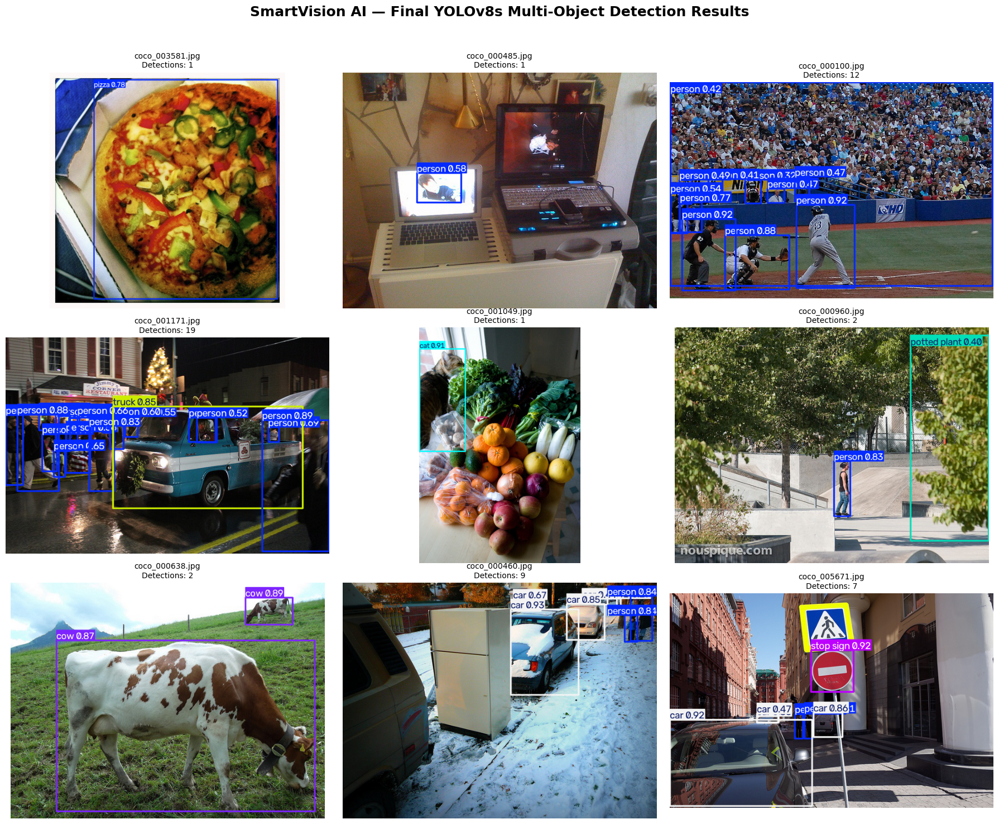


VISUALIZATION COMPLETE
Images visualized : 9
Total detections  : 54

Saved to:
E:\SmartVision-AI\results\detection\yolov8s_v2_final_predictions.png

Final detector:
E:\SmartVision-AI\runs\detection\yolov8s_v2_targeted_15ep\weights\best.pt

Final test performance:
Precision       : 86.74%
Recall          : 71.66%
mAP@0.50        : 80.78%
mAP@0.50:0.95   : 64.32%

✅ STEP 7U COMPLETE


In [6]:
# ============================================================
# PHASE 3.5 - STEP 7U
# FINAL V2 DETECTION PREDICTION VISUALIZATION
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import random

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

MODEL_PATH = Path(
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_v2_targeted_15ep"
    r"\weights\best.pt"
)

TEST_DIR = Path(
    r"E:\SmartVision-AI\data"
    r"\optimized_detection_v2"
    r"\images\test"
)

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)

OUTPUT_PATH = RESULTS_DIR / "yolov8s_v2_final_predictions.png"

assert MODEL_PATH.exists(), MODEL_PATH
assert TEST_DIR.exists(), TEST_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 85)
print("FINAL V2 PREDICTION VISUALIZATION")
print("=" * 85)

# ------------------------------------------------------------
# LOAD FINAL MODEL
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

# ------------------------------------------------------------
# GET TEST IMAGES
# ------------------------------------------------------------

test_images = sorted(
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.png"))
)

print("Test images available :", len(test_images))

# Reproducible selection
random.seed(42)

selected = random.sample(
    test_images,
    min(9, len(test_images))
)

# ------------------------------------------------------------
# RUN INFERENCE
# ------------------------------------------------------------

predictions = model.predict(
    source=[str(p) for p in selected],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    verbose=False
)

# ------------------------------------------------------------
# CREATE VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

axes = axes.flatten()

total_detections = 0

for ax, image_path, result in zip(
    axes,
    selected,
    predictions
):

    # Ultralytics plot() returns BGR
    plotted = result.plot()

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    detection_count = len(result.boxes)

    total_detections += detection_count

    ax.imshow(plotted)

    ax.set_title(
        f"{image_path.name}\n"
        f"Detections: {detection_count}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "SmartVision AI — Final YOLOv8s Multi-Object Detection Results",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    OUTPUT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("VISUALIZATION COMPLETE")
print("=" * 85)

print("Images visualized :", len(selected))
print("Total detections  :", total_detections)

print("\nSaved to:")
print(OUTPUT_PATH)

print("\nFinal detector:")
print(MODEL_PATH)

print("\nFinal test performance:")
print("Precision       : 86.74%")
print("Recall          : 71.66%")
print("mAP@0.50        : 80.78%")
print("mAP@0.50:0.95   : 64.32%")

print("\n✅ STEP 7U COMPLETE")

In [1]:
# ============================================================
# CHECK PYTHON ONLY — DO NOT INITIALIZE CUDA
# ============================================================

import sys

print("Python:", sys.version)
print("✅ Kernel is running")

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
✅ Kernel is running


FINAL V2 FAILURE ANALYSIS — CPU MODE
Test images : 356
Device      : CPU

Running inference...
Processed 50/356 | 0.2 min
Processed 100/356 | 0.3 min
Processed 150/356 | 0.4 min
Processed 200/356 | 0.5 min
Processed 250/356 | 0.6 min
Processed 300/356 | 0.8 min
Processed 350/356 | 0.9 min


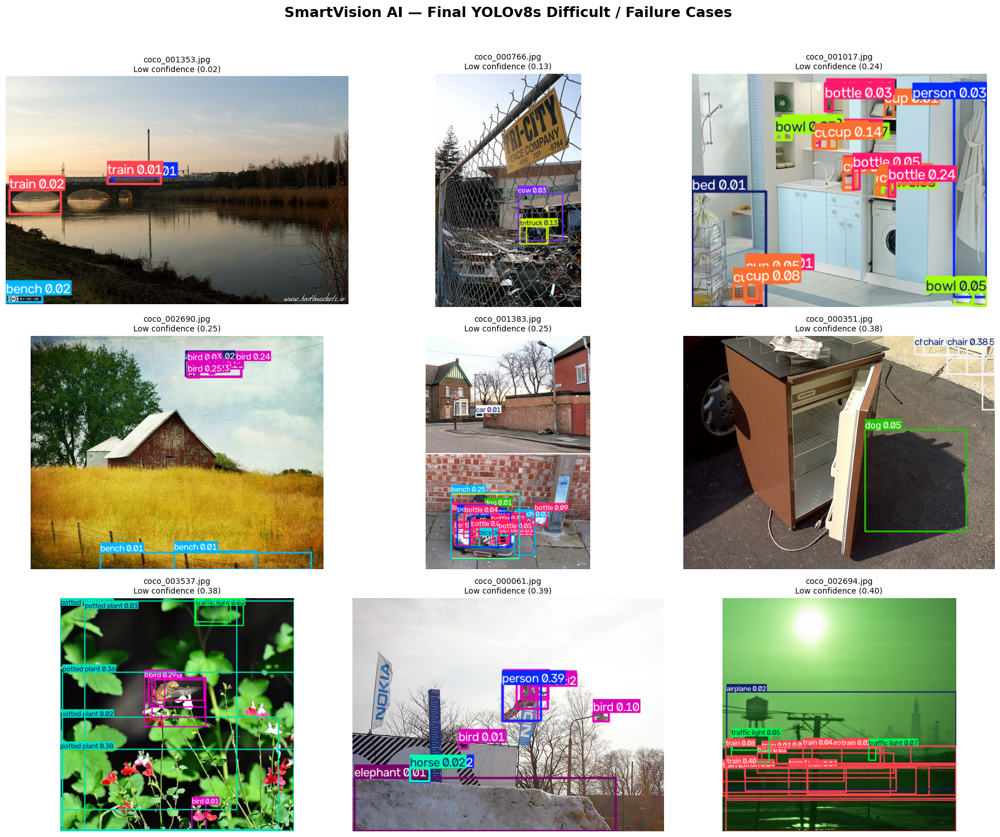


FAILURE ANALYSIS COMPLETE
No detections at conf >= 0.01 : 0
Only predictions below 0.50   : 13
At least one prediction >=0.50: 343

Total processing time: 1.00 minutes

Failure visualization:
E:\SmartVision-AI\results\detection\yolov8s_v2_final_failure_cases.png

Failure analysis JSON:
E:\SmartVision-AI\results\detection\yolov8s_v2_failure_analysis.json

Final detector:
E:\SmartVision-AI\runs\detection\yolov8s_v2_targeted_15ep\weights\best.pt

Final test metrics:
Precision       : 86.74%
Recall          : 71.66%
mAP@0.50        : 80.78%
mAP@0.50:0.95   : 64.32%

✅ STEP 7V COMPLETE


In [2]:
# ============================================================
# PHASE 3.5 - STEP 7V
# FINAL FAILURE ANALYSIS — CPU SAFE VERSION
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import json
import time

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

MODEL_PATH = Path(
    r"E:\SmartVision-AI\runs\detection"
    r"\yolov8s_v2_targeted_15ep"
    r"\weights\best.pt"
)

TEST_DIR = Path(
    r"E:\SmartVision-AI\data"
    r"\optimized_detection_v2"
    r"\images\test"
)

RESULTS_DIR = Path(
    r"E:\SmartVision-AI\results\detection"
)

OUTPUT_IMAGE = (
    RESULTS_DIR /
    "yolov8s_v2_final_failure_cases.png"
)

OUTPUT_JSON = (
    RESULTS_DIR /
    "yolov8s_v2_failure_analysis.json"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.exists(), MODEL_PATH
assert TEST_DIR.exists(), TEST_DIR

print("=" * 90)
print("FINAL V2 FAILURE ANALYSIS — CPU MODE")
print("=" * 90)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

test_images = sorted(
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.png"))
)

print("Test images :", len(test_images))
print("Device      : CPU")
print("\nRunning inference...")

# ------------------------------------------------------------
# PROCESS ONE IMAGE AT A TIME
# ------------------------------------------------------------

no_detection = []
low_confidence = []
strong_detection = []

failure_candidates = []

start = time.time()

for i, image_path in enumerate(test_images, 1):

    result = model.predict(
        source=str(image_path),
        imgsz=640,

        # Low threshold lets us inspect difficult predictions
        conf=0.01,

        iou=0.7,
        device="cpu",
        verbose=False
    )[0]

    boxes = result.boxes

    if boxes is None or len(boxes) == 0:

        no_detection.append(image_path)

        failure_candidates.append(
            (
                0.0,
                image_path,
                result,
                "No detection"
            )
        )

    else:

        confidences = (
            boxes.conf
            .detach()
            .cpu()
            .numpy()
        )

        max_conf = float(
            confidences.max()
        )

        if max_conf < 0.50:

            low_confidence.append(
                image_path
            )

            failure_candidates.append(
                (
                    max_conf,
                    image_path,
                    result,
                    f"Low confidence ({max_conf:.2f})"
                )
            )

        else:

            strong_detection.append(
                image_path
            )

    if i % 50 == 0:

        elapsed = (
            time.time() - start
        ) / 60

        print(
            f"Processed {i}/{len(test_images)} "
            f"| {elapsed:.1f} min"
        )

# ------------------------------------------------------------
# SELECT HARDEST CASES
# ------------------------------------------------------------

failure_candidates.sort(
    key=lambda x: x[0]
)

selected_failures = (
    failure_candidates[:9]
)

# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    3,
    figsize=(18, 15)
)

axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, item in zip(
    axes,
    selected_failures
):

    confidence, image_path, result, reason = item

    plotted = result.plot(
        conf=True,
        labels=True
    )

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(plotted)

    ax.set_title(
        f"{image_path.name}\n{reason}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "SmartVision AI — Final YOLOv8s Difficult / Failure Cases",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    OUTPUT_IMAGE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# SAVE ANALYSIS
# ------------------------------------------------------------

summary = {

    "final_model":
        str(MODEL_PATH),

    "test_images":
        len(test_images),

    "no_detection_at_conf_0_01":
        len(no_detection),

    "only_low_confidence_below_0_50":
        len(low_confidence),

    "at_least_one_prediction_above_0_50":
        len(strong_detection),

    "final_test_metrics": {

        "precision": 0.8674,
        "recall": 0.7166,
        "map50": 0.8078,
        "map50_95": 0.6432
    },

    "limitations": [

        "Small and distant objects remain more difficult to detect.",

        "Bench remains one of the weakest classes.",

        "Birds, bottles and traffic lights remain challenging in small-object scenes.",

        "Occlusion and crowded scenes may reduce recall.",

        "The detector has higher precision than recall, indicating that missed objects remain a larger issue than false positive detections."
    ]
}

with open(
    OUTPUT_JSON,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

# ------------------------------------------------------------
# FINAL OUTPUT
# ------------------------------------------------------------

elapsed = (
    time.time() - start
) / 60

print("\n" + "=" * 90)
print("FAILURE ANALYSIS COMPLETE")
print("=" * 90)

print(
    "No detections at conf >= 0.01 :",
    len(no_detection)
)

print(
    "Only predictions below 0.50   :",
    len(low_confidence)
)

print(
    "At least one prediction >=0.50:",
    len(strong_detection)
)

print(
    f"\nTotal processing time: "
    f"{elapsed:.2f} minutes"
)

print("\nFailure visualization:")
print(OUTPUT_IMAGE)

print("\nFailure analysis JSON:")
print(OUTPUT_JSON)

print("\nFinal detector:")
print(MODEL_PATH)

print("\nFinal test metrics:")
print("Precision       : 86.74%")
print("Recall          : 71.66%")
print("mAP@0.50        : 80.78%")
print("mAP@0.50:0.95   : 64.32%")

print("\n✅ STEP 7V COMPLETE")